# LNG criticality — walkthrough del modello
Questo notebook accompagna lo script `simple_criticality_bounded.py`. 

Percorso: **campione → risposte e covariate → fattore → likelihood → prior → stima → risultati → controlli → prossime decisioni**.

Ogni modello ha **un fattore**. Terminali e chokepoints sono separati; i loro score non condividono una scala comparabile.

**Versione aggiornata:** include le prove `regularized` e `response_precision` (statistiche estratte dai CSV forniti), oltre ai risultati posteriori della baseline `original`. 

In [20]:
from pathlib import Path
import json, inspect, hashlib, argparse, warnings, sys, shutil, platform
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Modifica questi percorsi SOLO per collegare i tuoi dati/run locali.
PROJECT_ROOT = Path(r"C:\Users\Leila\OneDrive\Desktop\Thesis\code")
TERMINAL_PANEL = Path(r"C:\Users\Leila\OneDrive\Desktop\Thesis\code\data\processed\model_ready\terminal_criticality_model_panel.csv")
CHOKEPOINT_PANEL = Path(r"C:\Users\Leila\OneDrive\Desktop\Thesis\code\data\processed\model_ready\chokepoint_criticality_model_panel.csv")
PRIOR_ONLY_RUNS = {
    "response_precision": {
        "terminal": PROJECT_ROOT / "outputs/model/simple_criticality/20261012T143020206703Z_terminal_bounded_response_precision/terminal",
        "chokepoint": PROJECT_ROOT / "outputs/model/simple_criticality/20261012T143122149892Z_chokepoint_bounded_response_precision/chokepoint",
    }
}
# RUNS punta ai fit completi quando disponibili; regularized resta prior-only.
RUNS = {
    "original": {
        "terminal": Path(r"C:\Users\Leila\OneDrive\Desktop\Thesis\code\outputs\model\simple_criticality\20261011T120422953825Z_terminal_bounded\terminal"),
        "chokepoint": Path(r"C:\Users\Leila\OneDrive\Desktop\Thesis\code\outputs\model\simple_criticality\20261011T154621463157Z_chokepoint_bounded\chokepoint"),
    },
    "regularized": {
        "terminal": Path(r"C:\Users\Leila\OneDrive\Desktop\Thesis\code\outputs\model\simple_criticality\20261012T140238458003Z_terminal_bounded_regularized\terminal"),
        "chokepoint": Path(r"C:\Users\Leila\OneDrive\Desktop\Thesis\code\outputs\model\simple_criticality\20261012T140405822794Z_chokepoint_bounded_regularized\chokepoint"),
    },
    "response_precision": {
        "terminal": Path(r"C:\Users\Leila\OneDrive\Desktop\Thesis\code\outputs\model\simple_criticality\20261012T163523899635Z_terminal_bounded_response_precision\terminal"),
        "chokepoint": Path(r"C:\Users\Leila\OneDrive\Desktop\Thesis\code\outputs\model\simple_criticality\20261012T180225613229Z_chokepoint_bounded_response_precision\chokepoint"),
    },
}

SELECTED_PROFILE = "response_precision"

TERMINAL_RUN = RUNS[SELECTED_PROFILE]["terminal"]
CHOKEPOINT_RUN = RUNS[SELECTED_PROFILE]["chokepoint"]

LOAD_POSTERIOR = False  # attiva solo per leggere NetCDF e curve; Run all resta leggero
RUN_FIT = False       # Run all non ristima il modello.
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})


## 1. Il campione: quale domanda stiamo studiando?
**Decisione:** conservare solo attività in `t` e `t−1`, lag di calendario disponibile; per i terminali anche età osservata.

**Controllo:** verificare i lag sul panel completo PRIMA del filtro. Non usare la precedente riga attiva come precedente mese.

Conteggi sotto: risultati documentati nel capitolo. Le esclusioni sono sequenziali.

In [21]:
selection = pd.DataFrame({
 'Step':['Initial panel','− Inactive in t','− No lag available',
              '− Inactive in t−1','Consecutively active','− Wrong age','Final sample','Final nodes'],
 'Terminals':[9540,4988,71,916,3565,112,3453,137],
 'Chokepoints':[1440,200,21,56,1163,0,1163,24]})
assert 9540-4988-71-916-112 == 3453
assert 1440-200-21-56 == 1163
display(selection)


,Step,Terminals,Chokepoints
0,Initial panel,9540,1440
1,− Inactive in t,4988,200
2,− No lag available,71,21
3,− Inactive in t−1,916,56
4,Consecutively active,3565,1163
5,− Wrong age,112,0
6,Final sample,3453,1163
7,Final nodes,137,24


## 2. Risposte e covariate
**Decisione:** sei risposte terminali e cinque risposte chokepoint. Nei chokepoints il bridge è escluso: differisce da articulation in 3/1.163 osservazioni (correlazione 0,993, secondo il capitolo).

Numeriche: centrate e scalate nel campione finale (`ddof=0`). Ruolo: dummy 0–1. Capacità/distanza: `log(1+x)` già nel panel. Risposte: scala originale; la standardizzazione di Y serve solo all'inizializzazione.

In [22]:
BINARY_RESPONSES = [
    "is_articulation_point", "has_incident_global_bridge",
    "connected_to_articulation_point",
]
COMMON_PREDICTORS = [
    "neighbor_activity_lag1", "log1p_mean_voyage_distance_lag1",
    "month_sin", "month_cos",
]
SPECS = {
    "terminal": {
        "id": "terminal_id",
        "continuous": ["role_specific_pagerank", "counterparty_hhi_terminal",
                       "role_specific_dependence"],
        "binary": BINARY_RESPONSES.copy(),
        "predictors": COMMON_PREDICTORS + ["log1p_capacity_mtpa", "terminal_age"],
    },
    "chokepoint": {
        "id": "node_id",
        "continuous": ["pagerank", "betweenness", "share_monthly_network_flow"],
        "binary": ["is_articulation_point", "connected_to_articulation_point"],
        "predictors": COMMON_PREDICTORS,
    },
}


def prior_specification(kind, profile="regularized"):
    """Fixed candidate priors, not fitted to empirical response frequencies.

    Keep the original intercept centres. Concentrate
    small-response intercepts/loadings and boundary logits to reduce extreme
    prior predictions. This is a sensitivity candidate, not a validated prior.
    All scales below are standard deviations (HalfNormal: scale).
    """
    if kind not in SPECS or profile not in ("original", "regularized", "response_precision"):
        raise ValueError("Unknown node type or prior profile")
    original = profile == "original"
    return {
        "profile": profile,
        "beta_sd": 0.5,
        "pagerank_loading_sd": 1.0 if original else 0.5,
        "other_loading_sd": ([1.0, 1.0] if original or kind == "terminal"
                             else [0.5, 0.5]),
        "binary_loading_sd": 1.0,
        "interior_intercept_mean": ([-4.0, 0.0, 0.0] if kind == "terminal"
                                    else [-4.0, -5.0, -4.0]),
        "interior_intercept_sd": ([1.5, 1.5, 1.5] if original else
                                  ([0.7, 1.5, 1.5] if kind == "terminal"
                                   else [0.7, 0.7, 0.7])),
        "binary_intercept_sd": 2.0,
        "boundary_intercept_mean": 0.0 if kind == "terminal" else -5.0,
        "boundary_intercept_sd": 1.5 if original else 1.0,
        "boundary_loading_sd": 1.0 if original else 0.5,
        # Candidate scales: at mu=.018, phi=300/500 gives conditional
        # Beta SD approximately .0077/.0059. At mu=.01/.02, phi=100
        # gives SD approximately .0099/.0139. These are illustrative
        # conditional scales, not matches to marginal empirical SDs.
        # Keep HHI/dependence unchanged to isolate small-response precision.
        "precision_median": (([300.0, 10.0, 10.0] if kind == "terminal"
                              else [500.0, 100.0, 100.0])
                             if profile == "response_precision"
                             else [10.0, 10.0, 10.0]),
        "precision_response_order": SPECS[kind]["continuous"].copy(),
    }

In [17]:
spec_table = pd.DataFrame([
 {'Model':kind, 'Numeric responses':', '.join(s['continuous']),
  'Binary responses':', '.join(s['binary']),
  'Covariates':', '.join(s['predictors'] + (['exporter_lag1'] if kind=='terminal' else []))}
 for kind,s in SPECS.items()])
display(spec_table.T)


,0,1
Model,terminal,chokepoint
Numeric responses,"role_specific_pagerank, counterparty_hhi_termi...","pagerank, betweenness, share_monthly_network_flow"
Binary responses,"is_articulation_point, has_incident_global_bri...","is_articulation_point, connected_to_articulati..."
Covariates,"neighbor_activity_lag1, log1p_mean_voyage_dist...","neighbor_activity_lag1, log1p_mean_voyage_dist..."


### Codice originale: validazione, selezione e scaling
La funzione si limita a preparare il campione; non avvia PyMC. Missing inattesi nelle altre colonne fanno fallire la validazione, invece di essere sostituiti silenziosamente.

In [23]:
def standardize(frame):
    """Fit scaling on the estimation sample; save it for interpretation/reuse."""
    mean, sd = frame.mean(), frame.std(ddof=0)
    if (sd <= 0).any() or not np.isfinite(sd).all():
        raise ValueError(f"Constant/invalid columns: {sd.index[sd <= 0].tolist()}")
    values = ((frame - mean) / sd).to_numpy(dtype=float)
    return values, pd.DataFrame({"mean": mean, "sd": sd})

def prepare_panel(path, kind):
    spec = SPECS[kind]
    frame = pd.read_csv(path, dtype={spec["id"]: "string"})
    needed = [spec["id"], "node_name", "period_month", "active",
              "activity_lag1", "lag_available", *spec["predictors"],
              *spec["continuous"], *spec["binary"]]
    if kind == "terminal":
        needed += ["terminal_role_lag1"]
    missing = sorted(set(needed) - set(frame.columns))
    if missing:
        raise ValueError(f"{path.name}: missing columns {missing}")
    keys = [spec["id"], "period_month"]
    if frame[keys].isna().any().any() or frame.duplicated(keys).any():
        raise ValueError(f"{path.name}: missing or duplicate node-month keys")
    frame["period_month"] = pd.to_datetime(frame["period_month"], errors="raise")
    if not frame["period_month"].dt.is_month_start.all():
        raise ValueError("period_month must contain first-of-month dates")
    for col in ["active", "lag_available"]:
        if not frame[col].isin([0, 1]).all():
            raise ValueError(f"{col} must be binary without missing values")
    if not frame["activity_lag1"].dropna().isin([0, 1]).all():
        raise ValueError("activity_lag1 must be binary where observed")
    # Verify the supplied lag refers to the preceding CALENDAR month, not
    # the previous selected active row. Do not recalculate any panel metric.
    ordered = frame.sort_values(keys)
    grouped = ordered.groupby(spec["id"], sort=False)
    previous_month = grouped["period_month"].shift()
    previous_active = grouped["active"].shift()
    expected = previous_month.eq(ordered["period_month"] - pd.offsets.MonthBegin(1))
    if not ordered["lag_available"].eq(expected.astype(int)).all():
        raise ValueError("lag_available disagrees with calendar-month availability")
    if not ordered.loc[expected, "activity_lag1"].eq(previous_active[expected]).all():
        raise ValueError("activity_lag1 disagrees with previous calendar activity")
    audit = {"panel_rows": len(frame), "panel_nodes": frame[spec["id"]].nunique()}
    selected = frame.loc[frame["active"].eq(1)].copy()
    audit["excluded_inactive_current"] = len(frame) - len(selected)
    valid_lag = selected["lag_available"].eq(1)
    audit["excluded_no_calendar_lag"] = int((~valid_lag).sum())
    selected = selected.loc[valid_lag].copy()
    previous_active_mask = selected["activity_lag1"].eq(1)
    audit["excluded_inactive_previous"] = int((~previous_active_mask).sum())
    selected = selected.loc[previous_active_mask].copy()
    audit["consecutive_active_rows"] = len(selected)
    audit["excluded_missing_age"] = 0
    if kind == "terminal":
        audit["excluded_missing_age"] = int(selected["terminal_age"].isna().sum())
        selected = selected.loc[selected["terminal_age"].notna()].copy()
        if selected["terminal_age"].lt(0).any():
            raise ValueError("Negative terminal age: review the panel metadata")
        if not selected["terminal_role_lag1"].isin(["importer", "exporter"]).all():
            raise ValueError("Unexpected lagged role in consecutive-active sample")
        selected["exporter_lag1"] = selected["terminal_role_lag1"].eq("exporter").astype(int)
    selected = selected.sort_values(["period_month", spec["id"]]).reset_index(drop=True)
    if selected.empty:
        raise ValueError(f"No observations remain for {kind}")
    predictors = spec["predictors"] + (["exporter_lag1"] if kind == "terminal" else [])
    model_columns = predictors + spec["continuous"] + spec["binary"]
    values = selected[model_columns].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f"Unexpected missing/nonfinite model values: "
                         f"{selected[model_columns].isna().sum().to_dict()}")
    if not selected[spec["binary"]].isin([0, 1]).all().all():
        raise ValueError("Structural responses must be binary")
    if not selected[spec["continuous"]].ge(0).all().all() or not selected[spec["continuous"]].le(1).all().all():
        raise ValueError("Continuous responses must lie in [0, 1]")
    if selected[spec["binary"]].nunique().lt(2).any():
        raise ValueError("A binary response is constant in the estimation sample")
    # Center/scale numeric covariates; keep role dummy on its 0/1 scale.
    x, x_scaling = standardize(selected[spec["predictors"]])
    if kind == "terminal":
        x = np.column_stack([x, selected["exporter_lag1"].to_numpy()])
        x_scaling.loc["exporter_lag1"] = [0.0, 1.0]
    yc, y_scaling = standardize(selected[spec["continuous"]])
    audit.update(estimation_rows=len(selected), estimation_nodes=selected[spec["id"]].nunique(),
                 predictors=predictors, continuous_responses=spec["continuous"],
                 binary_responses=spec["binary"],
                 input_sha256=hashlib.sha256(path.read_bytes()).hexdigest())
    return {"frame": selected, "x": x, "yc": yc,
            "yb": selected[spec["binary"]].to_numpy(dtype=int),
            "x_scaling": x_scaling, "y_scaling": y_scaling, "audit": audit}

In [28]:
prepared = {}
for kind, path in [('terminal', TERMINAL_PANEL), ('chokepoint', CHOKEPOINT_PANEL)]:
    if path is not None:
        prepared[kind] = prepare_panel(Path(path), kind)
        prepared[kind]['precision_prior_sd'] = 0.7
        prepared[kind]['prior_profile'] = SELECTED_PROFILE
        display(Markdown(f"**Audit: {kind}**"))
        display(pd.Series(prepared[kind]['audit']).to_frame('Value'))


**Audit: terminal**

,Value
panel_rows,9540
panel_nodes,159
excluded_inactive_current,4988
excluded_no_calendar_lag,71
excluded_inactive_previous,916
consecutive_active_rows,3565
excluded_missing_age,112
estimation_rows,3453
estimation_nodes,137
predictors,"[neighbor_activity_lag1, log1p_mean_voyage_dis..."


**Audit: chokepoint**

,Value
panel_rows,1440
panel_nodes,24
excluded_inactive_current,200
excluded_no_calendar_lag,21
excluded_inactive_previous,56
consecutive_active_rows,1163
excluded_missing_age,0
estimation_rows,1163
estimation_nodes,24
predictors,"[neighbor_activity_lag1, log1p_mean_voyage_dis..."


## 3. Un fattore per nodo–mese
$
f_{it}=x_{it}^{T}\beta+z_{it},\qquad z_{it}\sim N(0,1).
$

**Decisioni:** varianza residua fissata a 1; loading PageRank positivo; nessuna intercetta in `Xβ`; altri loading liberi. Le intercette delle risposte ne stabiliscono i livelli di base.

`factor_mean = Xβ` è la componente associata alle covariate. `factor` viene informato anche dalle risposte. `factor_residual` è la differenza.

**Statico:** nessun AR(1), effetto specifico del nodo o shock condiviso del mese.

**Rango uno:** sul link condizionale, il coefficiente covariata–risposta è `loading × β`. Tutte le risposte condividono una sola direzione di associazione con X. È la tua ipotesi di riduzione, da verificare.

**Indipendenza condizionale:** dato fattore e parametri, le risposte sono indipendenti.

## 4. Likelihood: rispettare supporto e valori al bordo

| Response | Distribution | Overall mean given f |
|---|---|---|
| PageRank (both), flow share | Beta | μ |
| HHI, dependence | Beta with mass at 1 | π + (1−π)μ |
| Betweenness | Beta with mass at 0 | (1−ρ)μ |
| Structural indicators | Bernoulli | p |

$
\operatorname{logit}(\mu_j)=\alpha_j+\lambda_jf,\quad
\operatorname{Var}(Y_j\mid\text{componente Beta},f)=\frac{\mu_j(1-\mu_j)}{1+\phi_j}.
$

Loading distinti per media interna e probabilità al bordo. **Non spostiamo i valori osservati 0/1.** La sostituzione con 0,5 nel codice serve solo a rendere valutabile il ramo Beta che non viene selezionato per un'osservazione al bordo. Il clipping nelle funzioni `random` evita arrotondamenti numerici delle sole simulazioni interne.

Il supporto effettivo è verificato anche in `main`: terminali positivi e PageRank <1; chokepoints <1, PageRank/flow positivi, betweenness con zeri e valori interni.

In [29]:
def one_inflated_beta_logp(value, alpha, beta, boundary_logit, inflated):
    """Mixed measure: Lebesgue density on (0,1), point probability at one.

    Substitute 0.5 ONLY in the unselected Beta branch for exact boundaries;
    observations are never clipped, shifted, or replaced in the likelihood.
    """
    import pymc as pm
    import pytensor.tensor as pt
    inside = (value > 0) & (value < 1)
    safe_value = pt.switch(inside, value, 0.5)
    log_beta = pm.logp(pm.Beta.dist(alpha=alpha, beta=beta), safe_value)
    log_one = -pt.logaddexp(0.0, -boundary_logit)
    log_interior = -pt.logaddexp(0.0, boundary_logit)
    continuous = log_beta + pt.switch(inflated, log_interior, 0.0)
    return pt.switch(inside, continuous,
                     pt.switch(pt.eq(value, 1) & inflated, log_one, -np.inf))

def one_inflated_beta_random(alpha, beta, boundary_logit, inflated, rng=None, size=None):
    rng = np.random.default_rng() if rng is None else rng
    # Stable sigmoid, including extreme logits in predictive draws.
    prob = np.exp(-np.logaddexp(0.0, -np.asarray(boundary_logit)))
    prob = np.where(inflated, prob, 0.0)
    interior = rng.beta(alpha, beta, size=size)
    # Floating-point beta routines may round to 0/1; keep interior draws interior.
    interior = np.clip(interior, np.nextafter(0.0, 1.0), np.nextafter(1.0, 0.0))
    return np.where(rng.uniform(size=np.shape(interior)) < prob, 1.0, interior)

def zero_inflated_beta_logp(value, alpha, beta, boundary_logit, inflated):
    # Reflecting the Beta and boundary gives exactly a zero-inflated Beta.
    return one_inflated_beta_logp(1 - value, beta, alpha, boundary_logit, inflated)

def zero_inflated_beta_random(alpha, beta, boundary_logit, inflated, rng=None, size=None):
    rng = np.random.default_rng() if rng is None else rng
    prob = np.exp(-np.logaddexp(0.0, -np.asarray(boundary_logit)))
    prob = np.where(inflated, prob, 0.0)
    interior = np.clip(rng.beta(alpha, beta, size=size),
                       np.nextafter(0.0, 1.0), np.nextafter(1.0, 0.0))
    return np.where(rng.uniform(size=np.shape(interior)) < prob, 0.0, interior)

## 5. Costruzione dei due modelli — codice originale
Queste celle definiscono le funzioni, senza stimare. Sono i blocchi centrali da mostrare ai supervisors: regressione del fattore, loading, intercette, precisioni e osservazioni.

Il ruolo entra solo nella regressione del fattore. Non ci sono loading, intercette o precisioni specifici per importer/exporter.

In [ ]:
def build_terminal_model(data):
    import pymc as pm
    import pytensor.tensor as pt

    priors = prior_specification("terminal", data.get("prior_profile", "regularized"))
    coords = {"obs": np.arange(len(data["frame"])),
              "predictor": data["audit"]["predictors"],
              "continuous": data["audit"]["continuous_responses"],
              "other_continuous": data["audit"]["continuous_responses"][1:],
              "binary": data["audit"]["binary_responses"],
              "boundary": data["audit"]["continuous_responses"][1:]}
    with pm.Model(coords=coords) as model:
        beta = pm.Normal("beta", 0, priors["beta_sd"], dims="predictor")
        factor_mean = pm.Deterministic("factor_mean", pt.dot(data["x"], beta), dims="obs")
        factor = pm.Normal("factor", mu=factor_mean, sigma=1, dims="obs")
        pm.Deterministic("factor_residual", factor - factor_mean, dims="obs")
        # PageRank is the first response in both specifications.
        anchor = pm.HalfNormal("pagerank_loading", priors["pagerank_loading_sd"])
        other = pm.Normal("other_loadings", 0, priors["other_loading_sd"], dims="other_continuous")
        lc = pm.Deterministic("loading_cont", pt.concatenate([anchor[None], other]), dims="continuous")
        lb = pm.Normal("loading_binary", 0, priors["binary_loading_sd"], dims="binary")
        ac = pm.Normal("intercept_cont", mu=priors["interior_intercept_mean"], sigma=priors["interior_intercept_sd"], dims="continuous")
        ab = pm.Normal("intercept_binary", 0, priors["binary_intercept_sd"], dims="binary")
        # Each response has its own precision; profile determines its prior median.
        phi = pm.LogNormal("precision_cont", mu=np.log(priors["precision_median"]),
                           sigma=data["precision_prior_sd"], dims="continuous")
        boundary_intercept = pm.Normal("intercept_one", priors["boundary_intercept_mean"], priors["boundary_intercept_sd"], dims="boundary")
        boundary_loading = pm.Normal("loading_one", 0, priors["boundary_loading_sd"], dims="boundary")
        eta_one = boundary_intercept + factor[:, None] * boundary_loading
        logits = pt.concatenate([pt.zeros_like(factor[:, None]), eta_one], axis=1)
        mu = pm.math.sigmoid(ac + factor[:, None] * lc)
        pm.CustomDist("y_cont", mu * phi, (1 - mu) * phi, logits,
                      np.array([False, True, True]),
                      logp=one_inflated_beta_logp, random=one_inflated_beta_random,
                      observed=data["frame"][data["audit"]["continuous_responses"]].to_numpy(),
                      dims=("obs", "continuous"))
        pm.Bernoulli("y_binary", logit_p=ab + factor[:, None] * lb,
                     observed=data["yb"], dims=("obs", "binary"))
    return model

In [ ]:
def build_chokepoint_model(data):
    import pymc as pm
    import pytensor.tensor as pt
    priors = prior_specification("chokepoint", data.get("prior_profile", "regularized"))
    coords = {"obs": np.arange(len(data["frame"])),
              "predictor": data["audit"]["predictors"],
              "continuous": data["audit"]["continuous_responses"],
              "other_continuous": data["audit"]["continuous_responses"][1:],
              "binary": data["audit"]["binary_responses"],
              "boundary": ["betweenness"]}
    with pm.Model(coords=coords) as model:
        beta = pm.Normal("beta", 0, priors["beta_sd"], dims="predictor")
        mean = pm.Deterministic("factor_mean", pt.dot(data["x"], beta), dims="obs")
        factor = pm.Normal("factor", mean, 1, dims="obs")
        pm.Deterministic("factor_residual", factor - mean, dims="obs")
        anchor = pm.HalfNormal("pagerank_loading", priors["pagerank_loading_sd"])
        other = pm.Normal("other_loadings", 0, priors["other_loading_sd"], dims="other_continuous")
        lc = pm.Deterministic("loading_cont", pt.concatenate([anchor[None], other]), dims="continuous")
        lb = pm.Normal("loading_binary", 0, priors["binary_loading_sd"], dims="binary")
        ac = pm.Normal("intercept_cont", priors["interior_intercept_mean"], priors["interior_intercept_sd"], dims="continuous")
        ab = pm.Normal("intercept_binary", 0, priors["binary_intercept_sd"], dims="binary")
        phi = pm.LogNormal("precision_cont", np.log(priors["precision_median"]), data["precision_prior_sd"], dims="continuous")
        azero = pm.Normal("intercept_zero", priors["boundary_intercept_mean"], priors["boundary_intercept_sd"], dims="boundary")
        lzero = pm.Normal("loading_zero", 0, priors["boundary_loading_sd"], dims="boundary")
        eta = azero + factor[:, None] * lzero
        logits = pt.concatenate([pt.zeros_like(eta), eta, pt.zeros_like(eta)], axis=1)
        mu = pm.math.sigmoid(ac + factor[:, None] * lc)
        pm.CustomDist("y_cont", mu * phi, (1-mu)*phi, logits,
                      np.array([False, True, False]),
                      logp=zero_inflated_beta_logp, random=zero_inflated_beta_random,
                      observed=data["frame"][data["audit"]["continuous_responses"]].to_numpy(),
                      dims=("obs", "continuous"))
        pm.Bernoulli("y_binary", logit_p=ab + factor[:, None]*lb,
                     observed=data["yb"], dims=("obs", "binary"))
    return model

def build_model(data):
    return (build_terminal_model(data) if "exporter_lag1" in data["audit"]["predictors"]
            else build_chokepoint_model(data))

## 6. Prior originali: riferimento della baseline
Sono prior provvisorie regolarizzanti, non scelte già validate da una sensitivity analysis. `precision_cont` è stimata, non fissata a 10.

| Parametro | Prior |
|---|---|
| β | Normal(0, 0,5²) |
| Loading PageRank | HalfNormal(scala 1) |
| Altri loading, inclusi quelli al bordo | Normal(0, 1) |
| Intercette interne terminali | Normal(centri −4, 0, 0; SD 1,5) |
| Intercette interne chokepoints | Normal(centri −4, −5, −4; SD 1,5) |
| Intercette binarie | Normal(0, 2²) |
| Intercette massa a uno | Normal(0, 1,5²) |
| Intercetta massa a zero | Normal(−5, 1,5²) |
| log precisione | Normal(log 10, 0,7²) |

A f=0 i centri −4 e −5 sulla scala logit corrispondono circa a 0,018 e 0,0067. Non sono le medie prior predictive complessive. Salvare `prior.nc` non sostituisce una valutazione della plausibilità delle repliche.

**Aggiornamento 12 ottobre:** la tabella sopra descrive il profilo `original`, usato nei fit posteriori riportati. I blocchi di codice ora permettono tre profili. La nuova prova `response_precision` è documentata di seguito; ha ora risultati posteriori documentati nella sezione 12A.

### 6A. Tre profili, stessa struttura del modello

| Scelta | `original` | `regularized` | `response_precision` |
|---|---|---|---|
| Intercette piccole: SD | 1,5 | 0,7 | 0,7 |
| Loading PageRank: scala | 1 | 0,5 | 0,5 |
| Loading betweenness/flow: SD | 1 | 0,5 | 0,5 |
| Intercette al bordo: SD | 1,5 | 1 | 1 |
| Loading al bordo: SD | 1 | 0,5 | 0,5 |
| Precisioni terminali: mediane PR, HHI, dependence | 10,10,10 | 10,10,10 | 300,10,10 |
| Precisioni chokepoints: mediane PR, betweenness, flow | 10,10,10 | 10,10,10 | 500,100,100 |

La SD logaritmica delle precisioni resta 0,7. I centri delle intercette, β, gli indicatori binari e la struttura del modello rimangono quelli documentati. Precisioni stimate con prior LogNormal: **non sono fissate alle mediane**.

`response_precision` isola la precisione rispetto a `regularized`; il confronto con `original` cambia più famiglie di prior. I valori sono candidati scelti dopo aver esaminato questi dati e queste simulazioni: documentare questa scelta informata dai dati, senza presentarla come elicitation indipendente.

La maggiore precisione riduce la varianza Beta condizionale. Non elimina la dispersione generata dalla variabilità di intercette, loading e fattori.

### 6B. Evidenza delle prove prior predictive
Fonti: `terminal`, `chokepoint` (`regularized`) e `terminal`, `chokepoint` (`response_precision`). Tabelle già incorporate: non richiedono NetCDF o fit. Le statistiche sono calcolate per dataset simulato. Gli intervalli sono quantili delle statistiche replicate.

Il fatto che una statistica osservata rientri in un intervallo non valida automaticamente la prior. Questi archivi contengono solo prior predictive; i fit completi successivi sono documentati nella sezione 12A.

In [ ]:
# Valori esatti estratti dai prior_checks.csv degli archivi forniti.
# Sono prove prior-only, non nuovi risultati posteriori.
prior_comparison = pd.DataFrame([{'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_pagerank', 'statistic': 'mean', 'observed': 0.0185216206415403, 'replicated_mean': 0.0306835302827775, 'low': 0.0052379683104129, 'high': 0.102796891637372}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_pagerank', 'statistic': 'sd', 'observed': 0.0132725690397673, 'replicated_mean': 0.058437753341412, 'low': 0.0172316449235411, 'high': 0.1599429304247418}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_pagerank', 'statistic': 'one_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_pagerank', 'statistic': 'zero_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_pagerank', 'statistic': 'q05', 'observed': 0.00885956578149, 'replicated_mean': 0.0001839643551448, 'low': 2.2288079718011838e-125, 'high': 0.0021201022398452}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_pagerank', 'statistic': 'q50', 'observed': 0.0147329412791, 'replicated_mean': 0.0079354212983909, 'low': 2.3013148411596848e-14, 'high': 0.0473675919785584}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_pagerank', 'statistic': 'q95', 'observed': 0.0391439256116599, 'replicated_mean': 0.1440545985932521, 'low': 0.0218891703211803, 'high': 0.4728158874326963}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'counterparty_hhi_terminal', 'statistic': 'mean', 'observed': 0.5887196965199468, 'replicated_mean': 0.741046554442671, 'low': 0.3482218048903244, 'high': 0.972388342767386}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'counterparty_hhi_terminal', 'statistic': 'sd', 'observed': 0.3253678040879977, 'replicated_mean': 0.2935280155442428, 'low': 0.0709022464034848, 'high': 0.4593006887506875}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'counterparty_hhi_terminal', 'statistic': 'one_share', 'observed': 0.3408630176657978, 'replicated_mean': 0.492228496959166, 'low': 0.1444685780480741, 'high': 0.8315015928178395}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'counterparty_hhi_terminal', 'statistic': 'zero_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'counterparty_hhi_terminal', 'statistic': 'q05', 'observed': 0.1267636591948, 'replicated_mean': 0.2234456664375843, 'low': 2.51889374595164e-19, 'high': 0.84344526602049}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'counterparty_hhi_terminal', 'statistic': 'q50', 'observed': 0.504544736358, 'replicated_mean': 0.8378195160364189, 'low': 0.1280501635943885, 'high': 1.0}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'counterparty_hhi_terminal', 'statistic': 'q95', 'observed': 1.0, 'replicated_mean': 0.9999492545276626, 'low': 1.0, 'high': 1.0}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_dependence', 'statistic': 'mean', 'observed': 0.4947803657121578, 'replicated_mean': 0.7506243075163029, 'low': 0.365750390970998, 'high': 0.9769533273169776}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_dependence', 'statistic': 'sd', 'observed': 0.3218697054888246, 'replicated_mean': 0.2866758566397481, 'low': 0.0646513368524518, 'high': 0.4625851323965662}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_dependence', 'statistic': 'one_share', 'observed': 0.207645525629887, 'replicated_mean': 0.5041960613958876, 'low': 0.1387054735013032, 'high': 0.8485447437011294}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_dependence', 'statistic': 'zero_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_dependence', 'statistic': 'q05', 'observed': 0.0716425248141399, 'replicated_mean': 0.2350523589221265, 'low': 6.950727335201391e-27, 'high': 0.850986199298421}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_dependence', 'statistic': 'q50', 'observed': 0.428314971481, 'replicated_mean': 0.848522417168255, 'low': 0.1270480370726875, 'high': 1.0}, {'node_type': 'terminal', 'profile': 'regularized', 'response': 'role_specific_dependence', 'statistic': 'q95', 'observed': 1.0, 'replicated_mean': 1.0, 'low': 1.0, 'high': 1.0}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_pagerank', 'statistic': 'mean', 'observed': 0.0185216206415403, 'replicated_mean': 0.0306075581350865, 'low': 0.0052093009819306, 'high': 0.104641255619066}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_pagerank', 'statistic': 'sd', 'observed': 0.0132725690397673, 'replicated_mean': 0.0289406790145997, 'low': 0.0038669833107554, 'high': 0.1369694560212979}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_pagerank', 'statistic': 'one_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_pagerank', 'statistic': 'zero_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_pagerank', 'statistic': 'q05', 'observed': 0.00885956578149, 'replicated_mean': 0.0058330658331416, 'low': 3.8774294524764484e-07, 'high': 0.0275040673990251}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_pagerank', 'statistic': 'q50', 'observed': 0.0147329412791, 'replicated_mean': 0.0215972989736171, 'low': 0.0033167368138272, 'high': 0.0660853312203211}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_pagerank', 'statistic': 'q95', 'observed': 0.0391439256116599, 'replicated_mean': 0.0878038078571157, 'low': 0.0135687930845443, 'high': 0.3929126851716093}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'counterparty_hhi_terminal', 'statistic': 'mean', 'observed': 0.5887196965199468, 'replicated_mean': 0.7410885612544055, 'low': 0.3491717214769881, 'high': 0.9717650216295036}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'counterparty_hhi_terminal', 'statistic': 'sd', 'observed': 0.3253678040879977, 'replicated_mean': 0.2935348293144846, 'low': 0.0734157536478056, 'high': 0.4584953203984058}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'counterparty_hhi_terminal', 'statistic': 'one_share', 'observed': 0.3408630176657978, 'replicated_mean': 0.4919591659426585, 'low': 0.141319142774399, 'high': 0.8343469446857805}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'counterparty_hhi_terminal', 'statistic': 'zero_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'counterparty_hhi_terminal', 'statistic': 'q05', 'observed': 0.1267636591948, 'replicated_mean': 0.2235968952199989, 'low': 2.933407951625721e-19, 'high': 0.8394199329125746}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'counterparty_hhi_terminal', 'statistic': 'q50', 'observed': 0.504544736358, 'replicated_mean': 0.8387202042098973, 'low': 0.1295481765701839, 'high': 1.0}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'counterparty_hhi_terminal', 'statistic': 'q95', 'observed': 1.0, 'replicated_mean': 0.9999467327014616, 'low': 1.0, 'high': 1.0}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_dependence', 'statistic': 'mean', 'observed': 0.4947803657121578, 'replicated_mean': 0.7504650751307872, 'low': 0.3593437578963638, 'high': 0.977486012466277}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_dependence', 'statistic': 'sd', 'observed': 0.3218697054888246, 'replicated_mean': 0.2867316009599164, 'low': 0.067464142181073, 'high': 0.461869894515855}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_dependence', 'statistic': 'one_share', 'observed': 0.207645525629887, 'replicated_mean': 0.5039226759339704, 'low': 0.139270199826238, 'high': 0.8480668983492614}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_dependence', 'statistic': 'zero_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_dependence', 'statistic': 'q05', 'observed': 0.0716425248141399, 'replicated_mean': 0.2357427073294087, 'low': 3.813680662781479e-26, 'high': 0.856761348740669}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_dependence', 'statistic': 'q50', 'observed': 0.428314971481, 'replicated_mean': 0.848305172393035, 'low': 0.1274906067993693, 'high': 1.0}, {'node_type': 'terminal', 'profile': 'response_precision', 'response': 'role_specific_dependence', 'statistic': 'q95', 'observed': 1.0, 'replicated_mean': 1.0, 'low': 1.0, 'high': 1.0}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'pagerank', 'statistic': 'mean', 'observed': 0.0176425748604835, 'replicated_mean': 0.0286441013574832, 'low': 0.0051129771487553, 'high': 0.0937054780047424}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'pagerank', 'statistic': 'sd', 'observed': 0.00686235538237, 'replicated_mean': 0.0541833476377058, 'low': 0.0173526821433165, 'high': 0.1383858253770668}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'pagerank', 'statistic': 'one_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'pagerank', 'statistic': 'zero_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'pagerank', 'statistic': 'q05', 'observed': 0.0084459939535749, 'replicated_mean': 0.0002206211577038, 'low': 3.327770953575362e-97, 'high': 0.0024416904850371}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'pagerank', 'statistic': 'q50', 'observed': 0.0165602187041, 'replicated_mean': 0.0078391642438377, 'low': 6.057732025583253e-14, 'high': 0.0488341631365818}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'pagerank', 'statistic': 'q95', 'observed': 0.0302029657514099, 'replicated_mean': 0.1320853051183692, 'low': 0.0205848848386404, 'high': 0.3791865668692021}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'betweenness', 'statistic': 'mean', 'observed': 0.0132078748764731, 'replicated_mean': 0.0110125464812744, 'low': 0.0016392868154703, 'high': 0.0370111316246281}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'betweenness', 'statistic': 'sd', 'observed': 0.0135323604941551, 'replicated_mean': 0.0328706470774272, 'low': 0.0095342386164499, 'high': 0.0764643876376495}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'betweenness', 'statistic': 'one_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'betweenness', 'statistic': 'zero_share', 'observed': 0.0051590713671539, 'replicated_mean': 0.0131943250214961, 'low': 0.0008598452278589, 'high': 0.0550730868443679}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'betweenness', 'statistic': 'q05', 'observed': 0.0005751227908151, 'replicated_mean': 1.366303931842573e-05, 'low': 0.0, 'high': 1.4894189911204943e-06}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'betweenness', 'statistic': 'q50', 'observed': 0.00767676767677, 'replicated_mean': 0.0008523598587319, 'low': 4.363841106172654e-34, 'high': 0.0077445561929222}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'betweenness', 'statistic': 'q95', 'observed': 0.0413096224404899, 'replicated_mean': 0.0577431658484088, 'low': 0.0007007494841111, 'high': 0.194160340148139}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'share_monthly_network_flow', 'statistic': 'mean', 'observed': 0.0234113717801591, 'replicated_mean': 0.0283503168752747, 'low': 0.0043487186741995, 'high': 0.0891394335102644}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'share_monthly_network_flow', 'statistic': 'sd', 'observed': 0.0200979366544628, 'replicated_mean': 0.0546040949991639, 'low': 0.0172495051448458, 'high': 0.1354821798836158}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'share_monthly_network_flow', 'statistic': 'one_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'share_monthly_network_flow', 'statistic': 'zero_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'share_monthly_network_flow', 'statistic': 'q05', 'observed': 0.002952180551199, 'replicated_mean': 0.0001770082725921, 'low': 2.439999810020203e-101, 'high': 0.001057138998667}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'share_monthly_network_flow', 'statistic': 'q50', 'observed': 0.0158874772036, 'replicated_mean': 0.0071233214546472, 'low': 7.826722825911551e-14, 'high': 0.0407141783597232}, {'node_type': 'chokepoint', 'profile': 'regularized', 'response': 'share_monthly_network_flow', 'statistic': 'q95', 'observed': 0.0642627000257, 'replicated_mean': 0.1331593124398669, 'low': 0.021330243597212, 'high': 0.3811526008918134}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'pagerank', 'statistic': 'mean', 'observed': 0.0176425748604835, 'replicated_mean': 0.0286442995063683, 'low': 0.0052332553550701, 'high': 0.092105929652066}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'pagerank', 'statistic': 'sd', 'observed': 0.00686235538237, 'replicated_mean': 0.0228360168231293, 'low': 0.0030036591615792, 'high': 0.1099981244233962}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'pagerank', 'statistic': 'one_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'pagerank', 'statistic': 'zero_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'pagerank', 'statistic': 'q05', 'observed': 0.0084459939535749, 'replicated_mean': 0.0074286828953087, 'low': 3.179266897144407e-05, 'high': 0.0324700321233253}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'pagerank', 'statistic': 'q50', 'observed': 0.0165602187041, 'replicated_mean': 0.0219338760124148, 'low': 0.0039456856684115, 'high': 0.0660383505018555}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'pagerank', 'statistic': 'q95', 'observed': 0.0302029657514099, 'replicated_mean': 0.0732838978066865, 'low': 0.0115252324800783, 'high': 0.2984642446113798}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'betweenness', 'statistic': 'mean', 'observed': 0.0132078748764731, 'replicated_mean': 0.0110392604324361, 'low': 0.0018640937788287, 'high': 0.0372757970231463}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'betweenness', 'statistic': 'sd', 'observed': 0.0135323604941551, 'replicated_mean': 0.0154257010258781, 'low': 0.0033914708485755, 'high': 0.0592866393310964}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'betweenness', 'statistic': 'one_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'betweenness', 'statistic': 'zero_share', 'observed': 0.0051590713671539, 'replicated_mean': 0.0133387790197764, 'low': 0.0008598452278589, 'high': 0.055889939810834}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'betweenness', 'statistic': 'q05', 'observed': 0.0005751227908151, 'replicated_mean': 0.0004053913487843, 'low': 0.0, 'high': 0.0032807018637008}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'betweenness', 'statistic': 'q50', 'observed': 0.00767676767677, 'replicated_mean': 0.0055993215418008, 'low': 1.3105550806518194e-05, 'high': 0.0228508340772197}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'betweenness', 'statistic': 'q95', 'observed': 0.0413096224404899, 'replicated_mean': 0.0401041420314256, 'low': 0.0088473283611633, 'high': 0.1349853835995846}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'share_monthly_network_flow', 'statistic': 'mean', 'observed': 0.0234113717801591, 'replicated_mean': 0.0282871646205274, 'low': 0.0046480117622983, 'high': 0.0877309438464461}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'share_monthly_network_flow', 'statistic': 'sd', 'observed': 0.0200979366544628, 'replicated_mean': 0.0278233617784854, 'low': 0.0059739910945054, 'high': 0.1058232521770509}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'share_monthly_network_flow', 'statistic': 'one_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'share_monthly_network_flow', 'statistic': 'zero_share', 'observed': 0.0, 'replicated_mean': 0.0, 'low': 0.0, 'high': 0.0}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'share_monthly_network_flow', 'statistic': 'q05', 'observed': 0.002952180551199, 'replicated_mean': 0.0035130915147714, 'low': 2.43021261199647e-12, 'high': 0.0188681891715248}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'share_monthly_network_flow', 'statistic': 'q50', 'observed': 0.0158874772036, 'replicated_mean': 0.0195711311055026, 'low': 0.001048393579236, 'high': 0.06189839087463}, {'node_type': 'chokepoint', 'profile': 'response_precision', 'response': 'share_monthly_network_flow', 'statistic': 'q95', 'observed': 0.0642627000257, 'replicated_mean': 0.083255057902306, 'low': 0.0178491491236236, 'high': 0.3045344643347684}])
sd_comparison = prior_comparison.query("statistic == 'sd'").pivot(
    index=['node_type','response'], columns='profile', values='replicated_mean')
observed_sd = prior_comparison.query("statistic == 'sd'").groupby(
    ['node_type','response'])['observed'].first()
sd_comparison.insert(0,'Observed SD',observed_sd)
display(sd_comparison.round(5))
new_checks = prior_comparison.query("profile == 'response_precision'").copy()
new_checks['observed_in_95_interval'] = (
    (new_checks.observed >= new_checks.low) & (new_checks.observed <= new_checks.high))
display(new_checks[['node_type','response','statistic','observed',
                    'replicated_mean','low','high','observed_in_95_interval']])


profile                                Observed SD  ...  response_precision
node_type  response                                 ...                    
chokepoint betweenness                     0.01353  ...             0.01543
           pagerank                        0.00686  ...             0.02284
           share_monthly_network_flow      0.02010  ...             0.02782
terminal   counterparty_hhi_terminal       0.32537  ...             0.29353
           role_specific_dependence        0.32187  ...             0.28673
           role_specific_pagerank          0.01327  ...             0.02894

[6 rows x 3 columns]

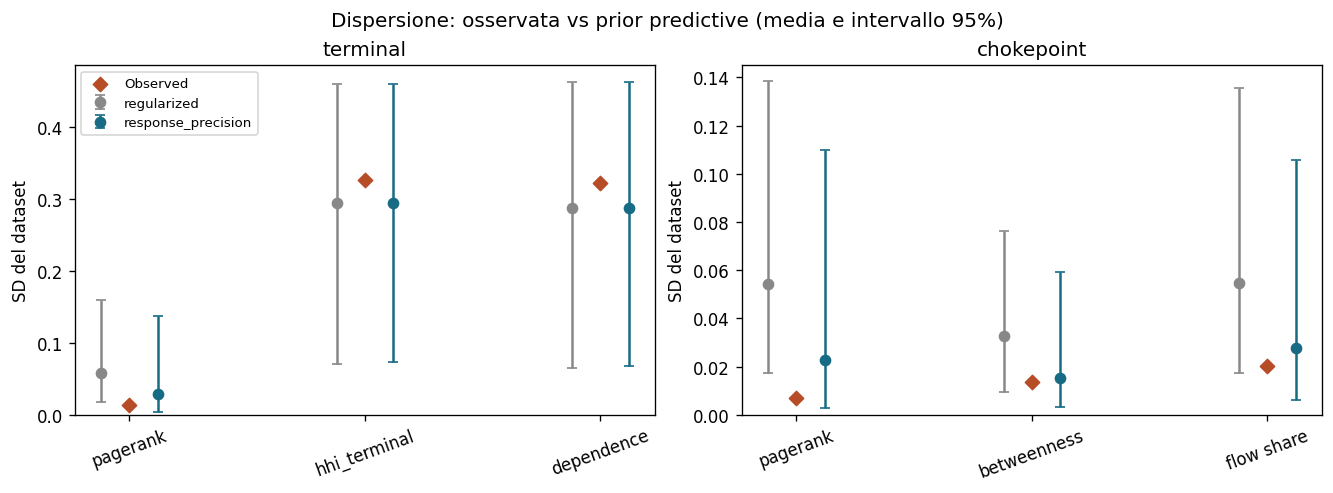

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for ax, kind in zip(axes, ['terminal','chokepoint']):
    d = prior_comparison.query("node_type == @kind and statistic == 'sd'")
    responses = d.response.unique()
    x = np.arange(len(responses))
    for offset, profile, color in [(-.12,'regularized','#888888'),
                                    (.12,'response_precision','#186b85')]:
        v=d[d.profile.eq(profile)].set_index('response').loc[responses]
        ax.errorbar(x+offset,v.replicated_mean,
                    yerr=[v.replicated_mean-v.low,v.high-v.replicated_mean],
                    fmt='o',capsize=3,label=profile,color=color)
    observed=d.groupby('response')['observed'].first().reindex(responses)
    ax.scatter(x,observed,marker='D',color='#b64d27',label='Observed',zorder=3)
    ax.set_xticks(x,[r.replace('role_specific_','').replace('counterparty_','').replace('share_monthly_network_flow','flow share') for r in responses],rotation=20)
    ax.set_title(kind); ax.set_ylabel('SD del dataset'); ax.set_ylim(bottom=0)
axes[0].legend(fontsize=8)
fig.suptitle('Dispersione: osservata vs prior predictive (media e intervallo 95%)')
plt.show()


### 6C. Interpretazione e passo successivo
- La precisione specifica riduce nettamente la dispersione: le SD e i quinti percentili osservati delle misure piccole rientrano ora nei rispettivi intervalli.
- La betweenness mostra una scala più vicina ai dati. Le code del PageRank rimangono ampie; non basta aumentare ulteriormente la precisione per controllare la variabilità delle medie.
- HHI/dependence e probabilità al bordo non sono state modificate in questa prova. Rimangono ampie e con massa a uno mediamente circa 50%.
- Manteniamo il profilo come candidato di sensibilità, senza cercare una coincidenza perfetta con gli istogrammi osservati.

**Distinzione:** sezioni 8–11 = posterior baseline originale; sezione 6B = simulazioni dalle nuove prior, prima del fit. Non attribuire ai nuovi profili i coefficienti o le diagnostiche dei vecchi fit.

Per produrre una nuova prova localmente (nella root del progetto):
```bash
python scripts/model/simple_criticality_bounded.py --node-type terminal --prior-profile response_precision --prior-only --prior-draws 1000
python scripts/model/simple_criticality_bounded.py --node-type chokepoint --prior-profile response_precision --prior-only --prior-draws 1000
```
I run già forniti hanno completato questo passaggio: non è necessario ripeterlo. I fit completi `response_precision` sono ora documentati nella sezione 12A.

## 7. Inizializzazione e stima
**Decisione computazionale:** PageRank standardizzato per inizializzare f; minimi quadrati per inizializzare β; perturbazioni fra catene. Non cambia la likelihood o le prior. La stabilità rispetto a partenze più diverse resta un controllo possibile.

**Run riportati:** 4 catene × 2.000 draw conservati, 1.500 warm-up, target acceptance 0,95, seed 20261008, un core. Attenzione: i default CLI dello script sono diversi (1.000 draw, 2.000 warm-up).

Di seguito il codice originale. La funzione `fit_model` salva anche prior predictive, posterior predictive e diagnostiche. Non viene chiamata a meno che tu attivi esplicitamente `RUN_FIT`.

In [ ]:
def chokepoint_initial_values(data, chains, seed):
    rng = np.random.default_rng(seed)
    f = data["yc"][:, 0]
    b = np.linalg.lstsq(data["x"], f, rcond=None)[0]
    y = data["frame"][data["audit"]["continuous_responses"]]
    means = np.array([y[c].loc[y[c].gt(0)].mean() for c in y])
    p = np.clip(data["yb"].mean(axis=0), .01, .99)
    pzero = y["betweenness"].eq(0).mean()
    starts = []
    for _ in range(chains):
        starts.append({"beta": b+rng.normal(0,.03,b.shape),
                       "factor": f+rng.normal(0,.05,f.shape),
                       "pagerank_loading": float(rng.uniform(.6,.8)),
                       "other_loadings": rng.normal(.2,.05,2),
                       "loading_binary": rng.normal(0,.05,len(p)),
                       "intercept_cont": np.log(means/(1-means))+rng.normal(0,.03,3),
                       "intercept_binary": np.log(p/(1-p))+rng.normal(0,.03,len(p)),
                       "precision_cont": np.asarray(prior_specification("chokepoint", data.get("prior_profile", "regularized"))["precision_median"])*np.exp(rng.normal(0,.03,3)),
                       "intercept_zero": np.array([np.log(pzero/(1-pzero))])+rng.normal(0,.03,1),
                       "loading_zero": rng.normal(0,.05,1)})
    return starts

def initial_values(data, chains, seed):
    """Data-informed starting points only; priors and likelihoods stay unchanged.

    Orient the initial factor toward PageRank, with small independent chain
    perturbations. This does not prove that other posterior modes are absent.
    """
    rng = np.random.default_rng(seed)
    factor_start = data["yc"][:, 0].copy()
    beta_start = np.linalg.lstsq(data["x"], factor_start, rcond=None)[0]
    loading = data["yc"].T @ factor_start / (factor_start @ factor_start)
    # PageRank initializes the factor but must not start with zero noise.
    probability = np.clip(data["yb"].mean(axis=0), 0.01, 0.99)
    intercept_binary = np.log(probability / (1 - probability))
    binary_loading = np.array([
        (np.corrcoef(factor_start, data["yb"][:, j])[0, 1]
         if data["yb"][:, j].std() > 0 else 0.0)
        for j in range(data["yb"].shape[1])
    ])
    starts = []
    for _ in range(chains):
        starts.append({
            "beta": beta_start + rng.normal(0, 0.03, beta_start.shape),
            "factor": factor_start + rng.normal(0, 0.05, factor_start.shape),
            "pagerank_loading": float(rng.uniform(0.6, 0.8)),
            "other_loadings": loading[1:] + rng.normal(0, 0.03, loading[1:].shape),
            "loading_binary": binary_loading + rng.normal(0, 0.03, binary_loading.shape),
            "intercept_cont": np.array([
                np.log(v / (1-v)) for v in [
                    data["frame"][col].loc[data["frame"][col].lt(1)].mean()
                    for col in data["audit"]["continuous_responses"]]]) + rng.normal(0, .03, 3),
            "intercept_one": np.array([
                np.log(v / (1-v)) for v in
                data["frame"][data["audit"]["continuous_responses"][1:]].eq(1).mean()
            ]) + rng.normal(0, .03, 2),
            "loading_one": rng.normal(0, .05, 2),
            "intercept_binary": intercept_binary + rng.normal(0, 0.03, probability.shape),
            "precision_cont": np.asarray(prior_specification("terminal", data.get("prior_profile", "regularized"))["precision_median"]) * np.exp(rng.normal(0, .03, 3)),
        })
    return starts

In [ ]:
def predictive_checks(idata, data, group):
    """Compare in-sample replicated distributions, on the original scale."""
    draws = getattr(idata, group)
    yc = draws["y_cont"].transpose("chain", "draw", "obs", "continuous").values
    # Bounded responses are modelled directly on their original scale.
    yb = draws["y_binary"].transpose("chain", "draw", "obs", "binary").values
    rows = []
    for j, col in enumerate(data["audit"]["continuous_responses"]):
        observed = data["frame"][col].to_numpy()
        replicated = yc[..., j]
        rows.append({"response": col, "observed_mean": observed.mean(),
                     "replicated_mean": replicated.mean(),
                     "observed_sd": observed.std(), "replicated_sd": replicated.std(),
                     "observed_zero_share": np.mean(observed == 0),
                     "observed_one_share": np.mean(observed == 1),
                     "replicated_outside_support_share": np.mean((replicated < 0) | (replicated > 1))})
    for j, col in enumerate(data["audit"]["binary_responses"]):
        proportions = yb[..., j].mean(axis=-1)
        rows.append({"response": col, "observed_mean": data["yb"][:, j].mean(),
                     "replicated_mean": proportions.mean(),
                     "replicated_mean_q025": np.quantile(proportions, .025),
                     "replicated_mean_q975": np.quantile(proportions, .975)})
    # Quantities calculated separately for each replicated dataset, not pooled.
    masks = {"all": np.ones(len(data["frame"]), dtype=bool)}
    for role in (["importer", "exporter"] if "terminal_role_lag1" in data["frame"] else []):
        masks[role] = data["frame"]["terminal_role_lag1"].eq(role).to_numpy()
    for role, mask in masks.items():
        if not mask.any():
            continue
        for j, col in enumerate(data["audit"]["continuous_responses"]):
            obs = data["frame"][col].to_numpy()[mask]
            rep = yc[..., mask, j]
            statistics = {"mean": (obs.mean(), rep.mean(axis=-1)),
                          "sd": (obs.std(), rep.std(axis=-1)),
                          "one_share": ((obs == 1).mean(), (rep == 1).mean(axis=-1)),
                          "zero_share": ((obs == 0).mean(), (rep == 0).mean(axis=-1))}
            for q in [.05, .5, .95]:
                statistics[f"q{int(q*100):02d}"] = (np.quantile(obs, q), np.quantile(rep, q, axis=-1))
            for stat, (actual, replicated) in statistics.items():
                rows.append({"response": col, "role_lag1": role, "statistic": stat,
                             "observed": actual, "replicated_mean": replicated.mean(),
                             "replicated_q025": np.quantile(replicated, .025),
                             "replicated_q975": np.quantile(replicated, .975)})
    return pd.DataFrame(rows)

def fit_model(data, kind, args, destination):
    try:
        import pymc as pm
        import arviz as az
    except ImportError as exc:
        raise RuntimeError("Install scripts/model/requirements.txt to estimate the model") from exc
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    model = build_model(data)
    with model:
        prior_count_key = ("draws" if "draws" in inspect.signature(pm.sample_prior_predictive).parameters
                           else "samples")
        prior = pm.sample_prior_predictive(**{prior_count_key: args.prior_draws}, random_seed=args.seed)
        predictive_checks(prior, data, "prior_predictive").to_csv(destination / "prior_checks.csv", index=False)
        prior.to_netcdf(destination / "prior.nc")
        if args.prior_only:
            return
        idata = pm.sample(draws=args.draws, tune=args.tune, chains=args.chains,
                          cores=args.cores, target_accept=args.target_accept,
                          init="adapt_diag",
                          initvals=(initial_values(data, args.chains, args.seed) if kind == "terminal"
                                    else chokepoint_initial_values(data, args.chains, args.seed)),
                          random_seed=args.seed, return_inferencedata=True)
        if (idata.posterior.sizes["chain"] != args.chains
                or idata.posterior.sizes["draw"] != args.draws):
            idata.to_netcdf(destination / "interrupted_posterior.nc")
            raise SystemExit("Incomplete sampling: saved interrupted_posterior.nc; "
                             "stopping without replacing posterior.nc or fitting another model")
        # Preserve completed sampling even if predictive simulation fails.
        idata.to_netcdf(destination / "posterior.nc")
        pm.sample_posterior_predictive(idata, var_names=["y_cont", "y_binary"],
                                       random_seed=args.seed, extend_inferencedata=True)
    idata.to_netcdf(destination / "posterior.nc")
    parameters = ["beta", "loading_cont", "loading_binary", "intercept_cont",
                  "intercept_binary", "precision_cont"] + (
                      ["intercept_one", "loading_one"] if kind == "terminal"
                      else ["intercept_zero", "loading_zero"])
    summary = az.summary(idata, var_names=parameters, hdi_prob=.95)
    summary.to_csv(destination / "parameter_summary.csv")
    for chain in idata.posterior.coords["chain"].values:
        az.summary(idata.sel(chain=[chain]), var_names=parameters,
                   kind="stats", hdi_prob=.95).to_csv(
                       destination / f"parameter_summary_chain_{chain}.csv")
    # Include latent residual mixing: good global parameters alone are insufficient.
    mixing = az.summary(idata, var_names=parameters + ["factor", "factor_mean", "factor_residual"], kind="diagnostics")
    diagnostic = {"divergences": int(idata.sample_stats["diverging"].sum()),
                  "max_rhat": float(mixing["r_hat"].max()),
                  "min_ess_bulk": float(mixing["ess_bulk"].min()),
                  "min_ess_tail": float(mixing["ess_tail"].min())}
    diagnostic["nonfinite_diagnostic_entries"] = int(
        (~np.isfinite(mixing[["r_hat", "ess_bulk", "ess_tail"]].to_numpy())).sum())
    mixing.to_csv(destination / "mixing_diagnostics.csv")
    diagnostic["passes_basic_checks"] = bool(
        diagnostic["nonfinite_diagnostic_entries"] == 0 and diagnostic["divergences"] == 0
        and np.isfinite(diagnostic["max_rhat"]) and diagnostic["max_rhat"] <= 1.01
        and diagnostic["min_ess_bulk"] >= 400 and diagnostic["min_ess_tail"] >= 400)
    (destination / "sampling_diagnostics.json").write_text(json.dumps(diagnostic, indent=2), encoding="utf-8")
    if not diagnostic["passes_basic_checks"]:
        warnings.warn(f"{kind}: sampling checks did not pass; do not interpret scores yet")
    scores = data["frame"][[SPECS[kind]["id"], "node_name", "period_month"]].copy()
    for variable in ["factor", "factor_mean"]:
        samples = idata.posterior[variable].transpose("obs", "chain", "draw").values.reshape(len(scores), -1)
        scores[f"{variable}_mean"] = samples.mean(axis=1)
        scores[f"{variable}_q025"] = np.quantile(samples, .025, axis=1)
        scores[f"{variable}_q975"] = np.quantile(samples, .975, axis=1)
    scores["passes_basic_sampling_checks"] = diagnostic["passes_basic_checks"]
    score_filename = ("factor_scores.csv" if diagnostic["passes_basic_checks"]
                      else "factor_scores_UNVALIDATED.csv")
    scores.to_csv(destination / score_filename, index=False)
    predictive_checks(idata, data, "posterior_predictive").to_csv(destination / "posterior_checks.csv", index=False)
    with az.rc_context({"plot.max_subplots": 100}):
        az.plot_trace(idata, var_names=parameters, compact=False)
    plt.savefig(destination / "trace.png", dpi=150, bbox_inches="tight")
    plt.close("all")

In [12]:
if RUN_FIT:
    kind = 'terminal'  # cambia se necessario
    if kind not in prepared:
        raise ValueError('Collega prima il panel e riesegui la preparazione.')
    y = prepared[kind]['frame'][SPECS[kind]['continuous']]
    if kind == 'terminal':
        assert not y.eq(0).any().any() and y.iloc[:,0].lt(1).all()
        assert all(0 < v < 1 for v in y.iloc[:,1:].eq(1).mean())
    else:
        assert y.lt(1).all().all()
        assert y[['pagerank','share_monthly_network_flow']].gt(0).all().all()
        assert 0 < y['betweenness'].eq(0).mean() < 1
    destination = PROJECT_ROOT / 'outputs' / 'notebook_runs' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') / kind
    destination.mkdir(parents=True, exist_ok=False)
    args = argparse.Namespace(draws=2000,tune=1500,chains=4,cores=1,
                              prior_draws=200,target_accept=.95,seed=20261008,prior_only=False)
    fit_model(prepared[kind], kind, args, destination)
else:
    print('Fit disattivato. Nessuna stima viene avviata.')


Fit disattivato. Nessuna stima viene avviata.


## 8. Diagnostiche essenziali
**Domanda:** il campionamento è adeguato? È distinta da “il modello riproduce bene i dati?”.

Screening: zero divergenze, R-hat ≤1,01, bulk/tail ESS ≥400, nessuna diagnostica non finita. Lo script controlla anche fattori, medie e residui.

Valori documentati e arrotondati dal capitolo; collegando i run viene mostrato anche il JSON effettivo.

In [13]:
diagnostics = pd.DataFrame({'Modello':['Terminali','Chokepoints'],
 'Divergenze':[0,0], 'Max R-hat':[1.01,1.01], 'Min bulk ESS':[817,472],
 'Min tail ESS':[1958,905]})
display(diagnostics)
for kind, run in [('terminal',TERMINAL_RUN),('chokepoint',CHOKEPOINT_RUN)]:
    if run is not None:
        path=Path(run)/'sampling_diagnostics.json'
        if path.exists(): display(pd.Series(json.loads(path.read_text())).to_frame(kind))
        else: print(f'{kind}: sampling_diagnostics.json non trovato.')


,Modello,Divergenze,Max R-hat,Min bulk ESS,Min tail ESS
0,Terminali,0,1.01,817,1958
1,Chokepoints,0,1.01,472,905


## 9. Risultato essenziale: quali covariate sono associate al fattore?
Figura con medie posteriori e HDI 95% **riportati nel capitolo**. Non sono coefficienti sulle unità originali di Y né effetti causali. Numeriche: incremento di una SD; ruolo: exporter rispetto a importer.

Per i terminali ruolo e capacità mostrano le associazioni più marcate. I termini stagionali vanno considerati congiuntamente, non solo uno per volta.

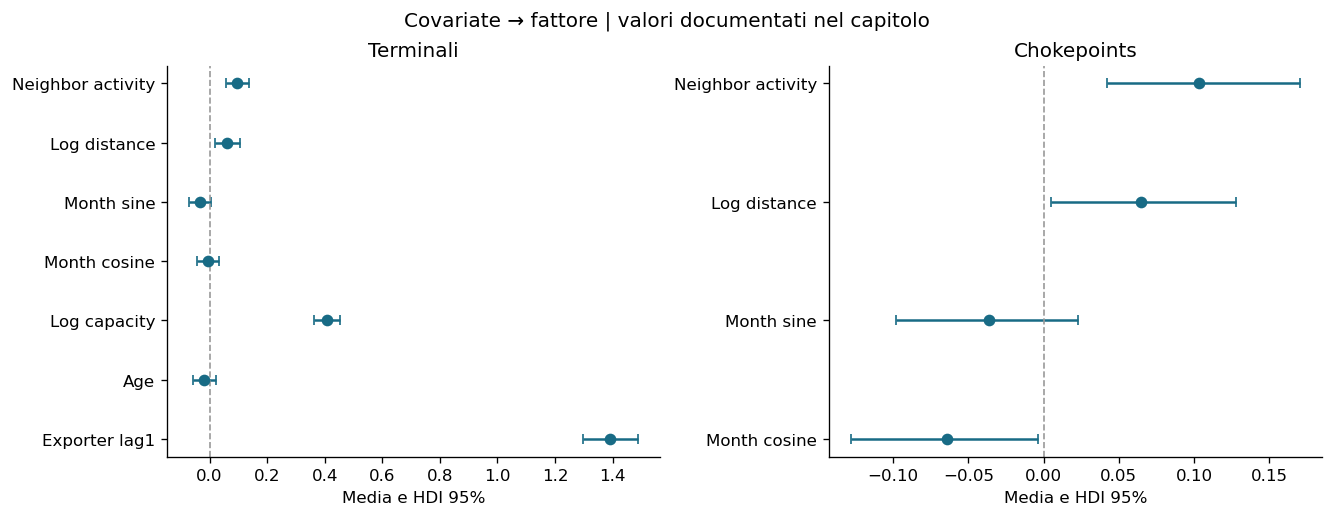

,Modello,Parametro,Mean,Low,High
0,Terminali,Neighbor activity,0.096,0.057,0.137
1,Terminali,Log distance,0.062,0.020,0.105
2,Terminali,Month sine,-0.032,-0.070,0.004
3,Terminali,Month cosine,-0.004,-0.042,0.032
4,Terminali,Log capacity,0.409,0.363,0.453
5,Terminali,Age,-0.019,-0.057,0.021
6,Terminali,Exporter lag1,1.392,1.296,1.488
7,Chokepoints,Neighbor activity,0.103,0.042,0.170
8,Chokepoints,Log distance,0.065,0.005,0.128
9,Chokepoints,Month sine,-0.036,-0.098,0.023


In [30]:
beta_reported = pd.DataFrame([
 ('Terminali','Neighbor activity',.096,.057,.137),
 ('Terminali','Log distance',.062,.020,.105),
 ('Terminali','Month sine',-.032,-.070,.004),
 ('Terminali','Month cosine',-.004,-.042,.032),
 ('Terminali','Log capacity',.409,.363,.453),
 ('Terminali','Age',-.019,-.057,.021),
 ('Terminali','Exporter lag1',1.392,1.296,1.488),
 ('Chokepoints','Neighbor activity',.103,.042,.170),
 ('Chokepoints','Log distance',.065,.005,.128),
 ('Chokepoints','Month sine',-.036,-.098,.023),
 ('Chokepoints','Month cosine',-.064,-.128,-.004)
], columns=['Modello','Parametro','Mean','Low','High'])
def forest(table, title):
    fig, axes=plt.subplots(1,2,figsize=(11,4.2),layout='constrained')
    for ax,kind in zip(axes,['Terminali','Chokepoints']):
        d=table[table.Modello.eq(kind)].reset_index(drop=True)
        ax.errorbar(d.Mean,np.arange(len(d)),xerr=[d.Mean-d.Low,d.High-d.Mean],
                    fmt='o',capsize=3,color='#186b85')
        ax.axvline(0,color='#999999',ls='--',lw=1)
        ax.set_yticks(np.arange(len(d)),d.Parametro); ax.invert_yaxis()
        ax.set_title(kind); ax.set_xlabel('Media e HDI 95%')
    fig.suptitle(title); plt.show()
forest(beta_reported,'Covariate → fattore | valori documentati nel capitolo')
display(beta_reported)


## 10. Risultato essenziale: che cosa significa il fattore?
Tutti i loading operano sul link logit, ma riferiti a componenti diverse. Le loro grandezze non sono automaticamente percentuali di “importanza”.

**Terminali:** centralità/diversificazione; associazioni strutturali miste. **Chokepoints:** centralità/esposizione ai flussi. Sono interpretazioni provvisorie di due fattori separati, non prova di rango due.

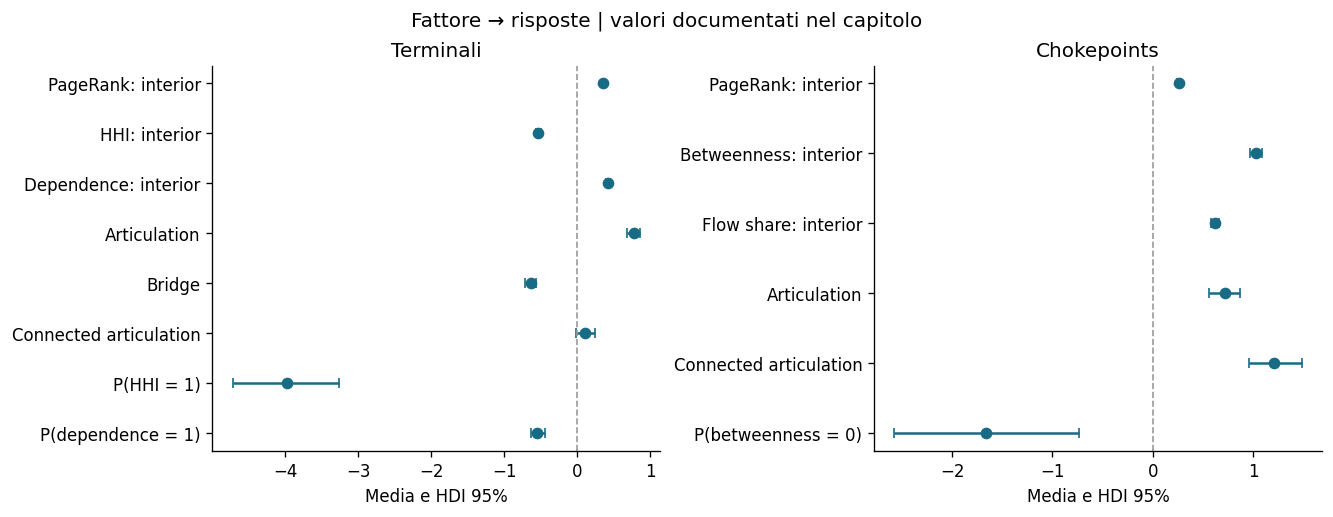

,Modello,Parametro,Mean,Low,High
0,Terminali,PageRank: interior,0.359,0.348,0.370
1,Terminali,HHI: interior,-0.535,-0.570,-0.502
2,Terminali,Dependence: interior,0.420,0.392,0.445
3,Terminali,Articulation,0.771,0.682,0.860
4,Terminali,Bridge,-0.637,-0.714,-0.560
5,Terminali,Connected articulation,0.110,-0.015,0.244
6,Terminali,P(HHI = 1),-3.982,-4.718,-3.266
7,Terminali,P(dependence = 1),-0.545,-0.638,-0.445
8,Chokepoints,PageRank: interior,0.262,0.244,0.283
9,Chokepoints,Betweenness: interior,1.026,0.971,1.085


In [15]:
loadings_reported = pd.DataFrame([
 ('Terminali','PageRank: interior',.359,.348,.370),
 ('Terminali','HHI: interior',-.535,-.570,-.502),
 ('Terminali','Dependence: interior',.420,.392,.445),
 ('Terminali','Articulation',.771,.682,.860),
 ('Terminali','Bridge',-.637,-.714,-.560),
 ('Terminali','Connected articulation',.110,-.015,.244),
 ('Terminali','P(HHI = 1)',-3.982,-4.718,-3.266),
 ('Terminali','P(dependence = 1)',-.545,-.638,-.445),
 ('Chokepoints','PageRank: interior',.262,.244,.283),
 ('Chokepoints','Betweenness: interior',1.026,.971,1.085),
 ('Chokepoints','Flow share: interior',.618,.579,.659),
 ('Chokepoints','Articulation',.718,.556,.871),
 ('Chokepoints','Connected articulation',1.204,.952,1.481),
 ('Chokepoints','P(betweenness = 0)',-1.659,-2.574,-.731)
],columns=['Modello','Parametro','Mean','Low','High'])
forest(loadings_reported,'Fattore → risposte | valori documentati nel capitolo')
display(loadings_reported)


### Dependence: il punto da non perdere
$
E(Y\mid f)=\pi(f)+(1-\pi(f))\mu(f).
$

Nel fit terminale μ cresce, π diminuisce. Perciò il loading interno positivo non dimostra che la dependence totale cresca. La curva riportata nel capitolo è lievemente a U nell'intervallo visualizzato. Per disegnarla correttamente servono intercette e draw congiunti: non basta moltiplicare le medie dei parametri.

## 11. Il controllo più informativo: le associazioni vengono riprodotte?
PPC congiunti documentati nel capitolo: 200 repliche condizionali in-sample. Intervalli al 95% delle statistiche replicate, **non HDI dei parametri**. Nessun aggiustamento per confronti multipli.

Articulation–bridge terminale: segno osservato positivo e replicato negativo. Le proporzioni marginali possono essere corrette, ma la co-occorrenza sbagliata. Questo limita l'interpretazione del fattore come sintesi dell'intera struttura.

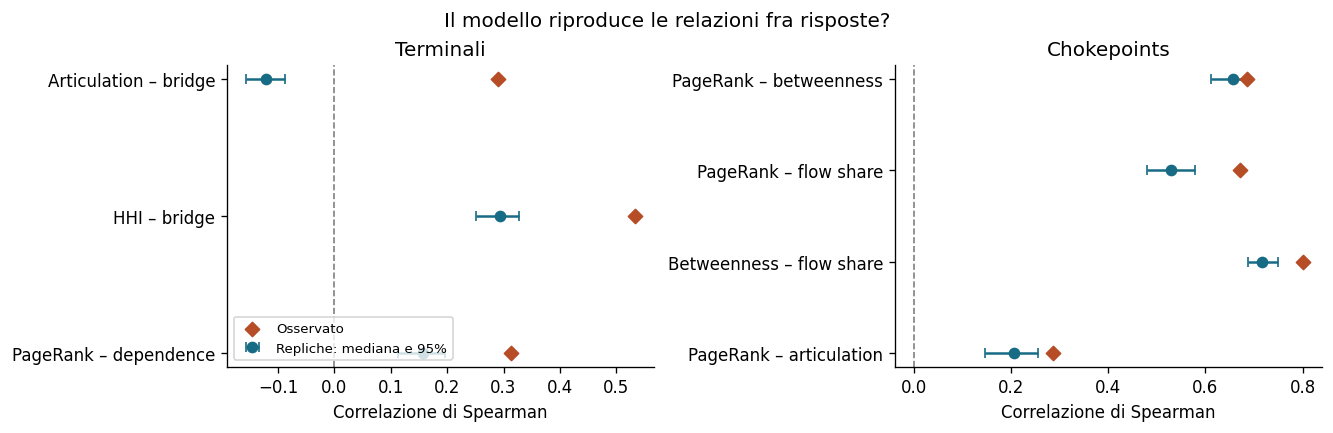

,Modello,Coppia,Observed,RepMedian,Low,High
0,Terminali,Articulation – bridge,0.290,-0.122,-0.156,-0.088
1,Terminali,HHI – bridge,0.533,0.293,0.251,0.328
2,Terminali,PageRank – dependence,0.314,0.157,0.113,0.197
3,Chokepoints,PageRank – betweenness,0.685,0.656,0.611,0.690
4,Chokepoints,PageRank – flow share,0.672,0.530,0.479,0.579
5,Chokepoints,Betweenness – flow share,0.800,0.717,0.688,0.750
6,Chokepoints,PageRank – articulation,0.287,0.205,0.145,0.256


In [16]:
joint = pd.DataFrame([
 ('Terminali','Articulation – bridge',.290,-.122,-.156,-.088),
 ('Terminali','HHI – bridge',.533,.293,.251,.328),
 ('Terminali','PageRank – dependence',.314,.157,.113,.197),
 ('Chokepoints','PageRank – betweenness',.685,.656,.611,.690),
 ('Chokepoints','PageRank – flow share',.672,.530,.479,.579),
 ('Chokepoints','Betweenness – flow share',.800,.717,.688,.750),
 ('Chokepoints','PageRank – articulation',.287,.205,.145,.256)
],columns=['Modello','Coppia','Observed','RepMedian','Low','High'])
fig,axes=plt.subplots(1,2,figsize=(11,3.5),layout='constrained')
for ax,kind in zip(axes,['Terminali','Chokepoints']):
    d=joint[joint.Modello.eq(kind)].reset_index(drop=True); yy=np.arange(len(d))
    ax.errorbar(d.RepMedian,yy,xerr=[d.RepMedian-d.Low,d.High-d.RepMedian],
                fmt='o',capsize=3,label='Repliche: mediana e 95%',color='#186b85')
    ax.scatter(d.Observed,yy,marker='D',color='#b64d27',label='Osservato',zorder=3)
    ax.set_yticks(yy,d.Coppia); ax.invert_yaxis(); ax.axvline(0,color='gray',ls='--',lw=1)
    ax.set_title(kind); ax.set_xlabel('Correlazione di Spearman')
axes[0].legend(fontsize=8,loc='lower left')
fig.suptitle('Il modello riproduce le relazioni fra risposte?'); plt.show()
display(joint)


### Due controlli marginali da mantenere
Aggregare può nascondere differenze per ruolo. Per gli exporter laggati, il modello sovrastima la frequenza di dependence=1. Nei chokepoints sottostima la dispersione della flow share.

Questi controlli sono condizionali ai fattori delle osservazioni già viste. Non costituiscono validazione su mesi futuri o nodi nuovi.

In [17]:
marginal = pd.DataFrame([
 ('Terminali: exporter lag1','HHI = 1 (%)',18.00,14.89,13.39,16.40),
 ('Terminali: exporter lag1','Dependence = 1 (%)',9.04,14.23,11.97,16.67),
 ('Chokepoints','Flow share: SD',.0201,.0182,.0171,.0194),
 ('Chokepoints','Flow share: median',.0159,.0190,.0178,.0201)
],columns=['Gruppo','Statistica','Observed','RepMean','Low','High'])
display(marginal)


,Gruppo,Statistica,Observed,RepMean,Low,High
0,Terminali: exporter lag1,HHI = 1 (%),18.0000,14.8900,13.3900,16.4000
1,Terminali: exporter lag1,Dependence = 1 (%),9.0400,14.2300,11.9700,16.6700
2,Chokepoints,Flow share: SD,0.0201,0.0182,0.0171,0.0194
3,Chokepoints,Flow share: median,0.0159,0.0190,0.0178,0.0201


## 12. Collegare gli output effettivi senza ristimare
Imposta `TERMINAL_RUN` / `CHOKEPOINT_RUN` nella prima cella alle sottocartelle `terminal` / `chokepoint` dei run. Queste tabelle sono autorevoli per il run collegato; quelle precedenti restano esplicitamente etichettate come valori del capitolo.

Le curve seguenti si attivano solo se `posterior.nc` e il CSV degli score sono disponibili. Mostrano la media complessiva delle miscele e l'incertezza parametrica, non intervalli predittivi di osservazioni individuali. Non ricalcolano un fit.

In [18]:
for kind,run in [('terminal',TERMINAL_RUN),('chokepoint',CHOKEPOINT_RUN)]:
    if run is None: continue
    run=Path(run)
    for filename in ['parameter_summary.csv','posterior_checks.csv']:
        path=run/filename
        if path.exists():
            display(Markdown(f'**{kind}: {filename}**'))
            table=pd.read_csv(path)
            if filename=='posterior_checks.csv' and 'statistic' in table:
                table=table[table.statistic.isin(['mean','sd','one_share','zero_share'])]
            display(table)
        else: print(f'{kind}: {filename} non trovato.')


In [ ]:
def posterior_response_curves(run, kind):
    import arviz as az
    run=Path(run)
    if not (run/'posterior.nc').exists():
        print(f'{kind}: posterior.nc non trovato.'); return
    scores_path=run/'factor_scores.csv'
    if not scores_path.exists():
        print(f'{kind}: score validati non disponibili; curve non generate.'); return
    scores=pd.read_csv(scores_path)
    lo,hi=np.quantile(scores.factor_mean,[.01,.99])
    grid=np.linspace(lo,hi,100)
    post=az.from_netcdf(run/'posterior.nc').posterior
    def arr(name, dim=None):
        a=post[name].stack(sample=('chain','draw'))
        return a.transpose('sample',dim).values if dim else a.transpose('sample').values
    sigmoid=lambda v: np.exp(-np.logaddexp(0.,-v))
    ac=arr('intercept_cont','continuous'); lc=arr('loading_cont','continuous')
    mu=sigmoid(ac[:,None,:]+grid[None,:,None]*lc[:,None,:])
    curves=mu.copy()
    if kind=='terminal':
        prob=sigmoid(arr('intercept_one','boundary')[:,None,:]+grid[None,:,None]*arr('loading_one','boundary')[:,None,:])
        curves[:,:,1:]=prob+(1-prob)*mu[:,:,1:]
    else:
        prob=sigmoid(arr('intercept_zero','boundary')[:,None,:]+grid[None,:,None]*arr('loading_zero','boundary')[:,None,:])
        curves[:,:,1]=(1-prob[:,:,0])*mu[:,:,1]
    binary=sigmoid(arr('intercept_binary','binary')[:,None,:]+grid[None,:,None]*arr('loading_binary','binary')[:,None,:])
    values=np.concatenate([curves,binary],axis=2)
    labels=SPECS[kind]['continuous']+SPECS[kind]['binary']
    fig,axes=plt.subplots(2,3,figsize=(12,6),layout='constrained')
    for j,ax in enumerate(axes.flat):
        if j>=len(labels): ax.set_visible(False); continue
        lower,median,upper=np.quantile(values[:,:,j],[.025,.5,.975],axis=0)
        ax.plot(grid,median,color='#186b85'); ax.fill_between(grid,lower,upper,color='#186b85',alpha=.2)
        ax.set_title(labels[j],fontsize=9); ax.set_xlabel('Fattore'); ax.set_ylabel('Media / probabilità')
    fig.suptitle(f'{kind}: curve posteriori, media complessiva e intervalli 95%'); plt.show()
for kind,run in [('terminal',TERMINAL_RUN),('chokepoint',CHOKEPOINT_RUN)]:
    if LOAD_POSTERIOR and run is not None: posterior_response_curves(run,kind)


## 12A. Posterior sensitivity — fit del 12 ottobre
**Fonti:** review_20261012T182620530908Z (terminali) e review_20261012T182725790336Z (chokepoints). Profilo verificato: `response_precision`. Hash dei panel uguali alle prove prior-only; campioni 3.453 e 1.163.

Questa sezione aggiunge i nuovi risultati senza sostituire la baseline delle sezioni 8–11. Il confronto cambia intercette/loading e precisioni rispetto a `original`: non isola la sola precisione. `regularized` ha solo simulazioni prior predictive, non un fit posteriore fornito.

**Diagnostiche:** terminali superano lo screening. Chokepoints: zero divergenze e max R-hat 1,01, ma bulk ESS della precisione betweenness 359 < 400. Risultati chokepoint provvisori; approfondire mixing, trace e autocorrelazione. Un nuovo run più lungo può aumentare ESS ma non garantisce di risolvere problemi di esplorazione.

In [ ]:
sensitivity_diagnostics = pd.DataFrame([{'Model': 'terminal', 'divergences': 0, 'max_rhat': 1.01, 'min_ess_bulk': 782.0, 'min_ess_tail': 2037.0, 'nonfinite_diagnostic_entries': 0, 'passes_basic_checks': True}, {'Model': 'chokepoint', 'divergences': 0, 'max_rhat': 1.01, 'min_ess_bulk': 359.0, 'min_ess_tail': 780.0, 'nonfinite_diagnostic_entries': 0, 'passes_basic_checks': False}])
display(sensitivity_diagnostics)

Model,divergences,max_rhat,min_ess_bulk,min_ess_tail,nonfinite_diagnostic_entries,passes_basic_checks
terminal,0,1.01,782.0,2037.0,0,True
chokepoint,0,1.01,359.0,780.0,0,False


In [ ]:
sensitivity_parameters = pd.DataFrame([{'Model': 'terminal', 'Parameter': 'beta[neighbor_activity_lag1]', 'Mean': 0.093, 'SD': 0.02, 'Low': 0.055, 'High': 0.132}, {'Model': 'terminal', 'Parameter': 'beta[log1p_mean_voyage_distance_lag1]', 'Mean': 0.058, 'SD': 0.021, 'Low': 0.015, 'High': 0.099}, {'Model': 'terminal', 'Parameter': 'beta[month_sin]', 'Mean': -0.036, 'SD': 0.019, 'Low': -0.071, 'High': 0.003}, {'Model': 'terminal', 'Parameter': 'beta[month_cos]', 'Mean': -0.005, 'SD': 0.019, 'Low': -0.042, 'High': 0.032}, {'Model': 'terminal', 'Parameter': 'beta[log1p_capacity_mtpa]', 'Mean': 0.408, 'SD': 0.023, 'Low': 0.363, 'High': 0.453}, {'Model': 'terminal', 'Parameter': 'beta[terminal_age]', 'Mean': -0.022, 'SD': 0.02, 'Low': -0.061, 'High': 0.019}, {'Model': 'terminal', 'Parameter': 'beta[exporter_lag1]', 'Mean': 1.407, 'SD': 0.05, 'Low': 1.311, 'High': 1.504}, {'Model': 'terminal', 'Parameter': 'loading_cont[role_specific_pagerank]', 'Mean': 0.359, 'SD': 0.006, 'Low': 0.348, 'High': 0.37}, {'Model': 'terminal', 'Parameter': 'loading_cont[counterparty_hhi_terminal]', 'Mean': -0.515, 'SD': 0.016, 'Low': -0.546, 'High': -0.482}, {'Model': 'terminal', 'Parameter': 'loading_cont[role_specific_dependence]', 'Mean': 0.42, 'SD': 0.014, 'Low': 0.392, 'High': 0.445}, {'Model': 'terminal', 'Parameter': 'loading_binary[is_articulation_point]', 'Mean': 0.77, 'SD': 0.045, 'Low': 0.684, 'High': 0.862}, {'Model': 'terminal', 'Parameter': 'loading_binary[has_incident_global_bridge]', 'Mean': -0.596, 'SD': 0.038, 'Low': -0.672, 'High': -0.523}, {'Model': 'terminal', 'Parameter': 'loading_binary[connected_to_articulation_point]', 'Mean': 0.1, 'SD': 0.065, 'Low': -0.023, 'High': 0.231}, {'Model': 'terminal', 'Parameter': 'intercept_cont[role_specific_pagerank]', 'Mean': -4.257, 'SD': 0.009, 'Low': -4.275, 'High': -4.239}, {'Model': 'terminal', 'Parameter': 'intercept_cont[counterparty_hhi_terminal]', 'Mean': -0.027, 'SD': 0.021, 'Low': -0.069, 'High': 0.014}, {'Model': 'terminal', 'Parameter': 'intercept_cont[role_specific_dependence]', 'Mean': -0.842, 'SD': 0.019, 'Low': -0.88, 'High': -0.805}, {'Model': 'terminal', 'Parameter': 'intercept_binary[is_articulation_point]', 'Mean': -2.871, 'SD': 0.086, 'Low': -3.046, 'High': -2.707}, {'Model': 'terminal', 'Parameter': 'intercept_binary[has_incident_global_bridge]', 'Mean': 0.633, 'SD': 0.042, 'Low': 0.549, 'High': 0.715}, {'Model': 'terminal', 'Parameter': 'intercept_binary[connected_to_articulation_point]', 'Mean': 2.818, 'SD': 0.078, 'Low': 2.663, 'High': 2.97}, {'Model': 'terminal', 'Parameter': 'precision_cont[role_specific_pagerank]', 'Mean': 1078.093, 'SD': 60.219, 'Low': 962.559, 'High': 1196.643}, {'Model': 'terminal', 'Parameter': 'precision_cont[counterparty_hhi_terminal]', 'Mean': 17.531, 'SD': 0.72, 'Low': 16.132, 'High': 18.979}, {'Model': 'terminal', 'Parameter': 'precision_cont[role_specific_dependence]', 'Mean': 6.737, 'SD': 0.188, 'Low': 6.372, 'High': 7.11}, {'Model': 'terminal', 'Parameter': 'intercept_one[counterparty_hhi_terminal]', 'Mean': -0.603, 'SD': 0.091, 'Low': -0.782, 'High': -0.428}, {'Model': 'terminal', 'Parameter': 'intercept_one[role_specific_dependence]', 'Mean': -1.219, 'SD': 0.044, 'Low': -1.309, 'High': -1.136}, {'Model': 'terminal', 'Parameter': 'loading_one[counterparty_hhi_terminal]', 'Mean': -3.116, 'SD': 0.218, 'Low': -3.561, 'High': -2.707}, {'Model': 'terminal', 'Parameter': 'loading_one[role_specific_dependence]', 'Mean': -0.528, 'SD': 0.049, 'Low': -0.623, 'High': -0.431}, {'Model': 'chokepoint', 'Parameter': 'beta[neighbor_activity_lag1]', 'Mean': 0.103, 'SD': 0.032, 'Low': 0.04, 'High': 0.168}, {'Model': 'chokepoint', 'Parameter': 'beta[log1p_mean_voyage_distance_lag1]', 'Mean': 0.066, 'SD': 0.032, 'Low': 0.007, 'High': 0.131}, {'Model': 'chokepoint', 'Parameter': 'beta[month_sin]', 'Mean': -0.035, 'SD': 0.032, 'Low': -0.098, 'High': 0.028}, {'Model': 'chokepoint', 'Parameter': 'beta[month_cos]', 'Mean': -0.065, 'SD': 0.031, 'Low': -0.125, 'High': -0.004}, {'Model': 'chokepoint', 'Parameter': 'loading_cont[pagerank]', 'Mean': 0.262, 'SD': 0.01, 'Low': 0.243, 'High': 0.281}, {'Model': 'chokepoint', 'Parameter': 'loading_cont[betweenness]', 'Mean': 1.031, 'SD': 0.028, 'Low': 0.977, 'High': 1.086}, {'Model': 'chokepoint', 'Parameter': 'loading_cont[share_monthly_network_flow]', 'Mean': 0.617, 'SD': 0.021, 'Low': 0.578, 'High': 0.658}, {'Model': 'chokepoint', 'Parameter': 'loading_binary[is_articulation_point]', 'Mean': 0.707, 'SD': 0.081, 'Low': 0.555, 'High': 0.868}, {'Model': 'chokepoint', 'Parameter': 'loading_binary[connected_to_articulation_point]', 'Mean': 1.205, 'SD': 0.136, 'Low': 0.949, 'High': 1.477}, {'Model': 'chokepoint', 'Parameter': 'intercept_cont[pagerank]', 'Mean': -4.053, 'SD': 0.011, 'Low': -4.074, 'High': -4.03}, {'Model': 'chokepoint', 'Parameter': 'intercept_cont[betweenness]', 'Mean': -4.793, 'SD': 0.035, 'Low': -4.859, 'High': -4.725}, {'Model': 'chokepoint', 'Parameter': 'intercept_cont[share_monthly_network_flow]', 'Mean': -3.906, 'SD': 0.025, 'Low': -3.956, 'High': -3.858}, {'Model': 'chokepoint', 'Parameter': 'intercept_binary[is_articulation_point]', 'Mean': 1.137, 'SD': 0.075, 'Low': 0.989, 'High': 1.283}, {'Model': 'chokepoint', 'Parameter': 'intercept_binary[connected_to_articulation_point]', 'Mean': 2.68, 'SD': 0.149, 'Low': 2.409, 'High': 2.982}, {'Model': 'chokepoint', 'Parameter': 'precision_cont[pagerank]', 'Mean': 793.949, 'SD': 36.545, 'Low': 724.756, 'High': 866.893}, {'Model': 'chokepoint', 'Parameter': 'precision_cont[betweenness]', 'Mean': 1094.249, 'SD': 176.964, 'Low': 764.827, 'High': 1443.906}, {'Model': 'chokepoint', 'Parameter': 'precision_cont[share_monthly_network_flow]', 'Mean': 163.651, 'SD': 8.013, 'Low': 149.283, 'High': 180.149}, {'Model': 'chokepoint', 'Parameter': 'intercept_zero[betweenness]', 'Mean': -5.739, 'SD': 0.471, 'Low': -6.622, 'High': -4.813}, {'Model': 'chokepoint', 'Parameter': 'loading_zero[betweenness]', 'Mean': -0.98, 'SD': 0.339, 'Low': -1.615, 'High': -0.3}])
display(sensitivity_parameters[sensitivity_parameters.Parameter.str.startswith("beta[")])

Model,Parameter,Mean,SD,Low,High
terminal,beta[neighbor_activity_lag1],0.093,0.020,0.055,0.132
terminal,beta[log1p_mean_voyage_distance_lag1],0.058,0.021,0.015,0.099
terminal,beta[month_sin],-0.036,0.019,-0.071,0.003
terminal,beta[month_cos],-0.005,0.019,-0.042,0.032
terminal,beta[log1p_capacity_mtpa],0.408,0.023,0.363,0.453
terminal,beta[terminal_age],-0.022,0.020,-0.061,0.019
terminal,beta[exporter_lag1],1.407,0.050,1.311,1.504
chokepoint,beta[neighbor_activity_lag1],0.103,0.032,0.040,0.168
chokepoint,beta[log1p_mean_voyage_distance_lag1],0.066,0.032,0.007,0.131
chokepoint,beta[month_sin],-0.035,0.032,-0.098,0.028


### Covariate: associazioni sostanzialmente stabili
Terminali: capacità 0,409 → 0,408; ruolo exporter 1,392 → 1,407; vicini 0,096 → 0,093; distanza 0,062 → 0,058. Le stesse associazioni positive mantengono HDI che escludono zero. Età e stagionalità non emergono chiaramente.

Chokepoints: vicini 0,103 → 0,103; distanza 0,065 → 0,066; cosine −0,064 → −0,065. Interpretazione provvisoria per screening incompleto. Termini stagionali da considerare congiuntamente.

La stabilità qui riguarda i coefficienti e le direzioni dei loading confrontati. Non abbiamo misurato la stabilità della classifica degli score fra run, perché mancano gli score originali necessari al confronto diretto.

In [ ]:
boundary_sensitivity = pd.DataFrame([{'Model': 'terminal', 'Component': 'P(HHI=1): loading', 'Original': -3.982, 'New': -3.116, 'Low': -3.561, 'High': -2.707}, {'Model': 'terminal', 'Component': 'Bridge: loading', 'Original': -0.637, 'New': -0.596, 'Low': -0.672, 'High': -0.523}, {'Model': 'chokepoint', 'Component': 'P(betweenness=0): loading', 'Original': -1.659, 'New': -0.98, 'Low': -1.615, 'High': -0.3}])
display(boundary_sensitivity)

Model,Component,Original,New,Low,High
terminal,P(HHI=1): loading,-3.982,-3.116,-3.561,-2.707
terminal,Bridge: loading,-0.637,-0.596,-0.672,-0.523
chokepoint,P(betweenness=0): loading,-1.659,-0.980,-1.615,-0.300


### Componenti al bordo: sensibilità nell’intensità
La direzione resta negativa, ma il loading HHI=1 passa da −3,982 a −3,116 e quello betweenness=0 da −1,659 a −0,980. Il secondo è informato da soli sei zeri. La maggiore regolarizzazione dei loading al bordo fa parte della modifica: non attribuire il cambiamento soltanto alla precisione.

Le precisioni posteriori non coincidono con le mediane prior: PageRank terminali circa 1.078 (prior mediana 300); PageRank chokepoints circa 794 (500); betweenness circa 1.094 (100). Questi scostamenti non dimostrano da soli che le prior siano irrilevanti.

In [ ]:
new_joint_checks = pd.DataFrame([{'Model': 'terminal', 'Pair': 'role_specific_pagerank / counterparty_hhi_terminal', 'Observed': -0.6393817339462485, 'RepMedian': -0.7038824626148499, 'Low': -0.7236077958479575, 'High': -0.6858087963633527}, {'Model': 'terminal', 'Pair': 'role_specific_pagerank / role_specific_dependence', 'Observed': 0.314488863698438, 'RepMedian': 0.1616635778214495, 'Low': 0.1162633326804958, 'High': 0.2028965844238686}, {'Model': 'terminal', 'Pair': 'role_specific_pagerank / is_articulation_point', 'Observed': 0.3724432036874907, 'RepMedian': 0.2666306842612235, 'Low': 0.2326656958265531, 'High': 0.3006660060320853}, {'Model': 'terminal', 'Pair': 'role_specific_pagerank / has_incident_global_bridge', 'Observed': -0.2380457832285195, 'RepMedian': -0.2799933771917883, 'Low': -0.3198121438960098, 'High': -0.2386320320844079}, {'Model': 'terminal', 'Pair': 'role_specific_pagerank / connected_to_articulation_point', 'Observed': -0.0149707578285588, 'RepMedian': 0.0244476497190703, 'Low': -0.0234670999166218, 'High': 0.060735021664446}, {'Model': 'terminal', 'Pair': 'counterparty_hhi_terminal / role_specific_dependence', 'Observed': -0.1706777631315441, 'RepMedian': -0.1576175731289976, 'Low': -0.1998184080617761, 'High': -0.1167254586305674}, {'Model': 'terminal', 'Pair': 'counterparty_hhi_terminal / is_articulation_point', 'Observed': -0.2904254141210802, 'RepMedian': -0.2577576700295904, 'Low': -0.292593613115762, 'High': -0.2205713523256288}, {'Model': 'terminal', 'Pair': 'counterparty_hhi_terminal / has_incident_global_bridge', 'Observed': 0.5325899965063673, 'RepMedian': 0.272919758957686, 'Low': 0.2288743575261117, 'High': 0.3122812379156653}, {'Model': 'terminal', 'Pair': 'counterparty_hhi_terminal / connected_to_articulation_point', 'Observed': -0.0376418208997266, 'RepMedian': -0.0252640623643284, 'Low': -0.0665181684955897, 'High': 0.0204734385401239}, {'Model': 'terminal', 'Pair': 'role_specific_dependence / is_articulation_point', 'Observed': 0.1566498699435202, 'RepMedian': 0.0877582585888852, 'Low': 0.060111462908164, 'High': 0.1149841918210701}, {'Model': 'terminal', 'Pair': 'role_specific_dependence / has_incident_global_bridge', 'Observed': -0.0664058109485939, 'RepMedian': -0.0683997608941903, 'Low': -0.1044101599923807, 'High': -0.034662768891298}, {'Model': 'terminal', 'Pair': 'role_specific_dependence / connected_to_articulation_point', 'Observed': -0.0815388000082101, 'RepMedian': 0.0068652545046578, 'Low': -0.03084807120284, 'High': 0.0362404895552368}, {'Model': 'terminal', 'Pair': 'is_articulation_point / has_incident_global_bridge', 'Observed': 0.2895710873177309, 'RepMedian': -0.1207845876163609, 'Low': -0.1532433693032052, 'High': -0.0771002670325448}, {'Model': 'terminal', 'Pair': 'is_articulation_point / connected_to_articulation_point', 'Observed': -0.0627994736217605, 'RepMedian': 0.0119470602106283, 'Low': -0.0264817912631092, 'High': 0.0375413544386405}, {'Model': 'terminal', 'Pair': 'has_incident_global_bridge / connected_to_articulation_point', 'Observed': 0.0595281191148087, 'RepMedian': -0.0104366419639725, 'Low': -0.0422759590892936, 'High': 0.0284258022776691}, {'Model': 'chokepoint', 'Pair': 'pagerank / betweenness', 'Observed': 0.6845696041706966, 'RepMedian': 0.6566110269250476, 'Low': 0.6146893778343975, 'High': 0.6954039200922474}, {'Model': 'chokepoint', 'Pair': 'pagerank / share_monthly_network_flow', 'Observed': 0.6717675819526067, 'RepMedian': 0.5317860515823832, 'Low': 0.4969834389433373, 'High': 0.5835639204688707}, {'Model': 'chokepoint', 'Pair': 'pagerank / is_articulation_point', 'Observed': 0.2866960752745582, 'RepMedian': 0.201043231612831, 'Low': 0.1355418926533906, 'High': 0.262743635847015}, {'Model': 'chokepoint', 'Pair': 'pagerank / connected_to_articulation_point', 'Observed': 0.2156684419334141, 'RepMedian': 0.218835783550951, 'Low': 0.1336005404764373, 'High': 0.2733536476501371}, {'Model': 'chokepoint', 'Pair': 'betweenness / share_monthly_network_flow', 'Observed': 0.800043573206881, 'RepMedian': 0.7216820583436843, 'Low': 0.6866691431723578, 'High': 0.7453912569975741}, {'Model': 'chokepoint', 'Pair': 'betweenness / is_articulation_point', 'Observed': 0.2521418129648981, 'RepMedian': 0.2709329440878076, 'Low': 0.1964935566338055, 'High': 0.3328565794761907}, {'Model': 'chokepoint', 'Pair': 'betweenness / connected_to_articulation_point', 'Observed': 0.3203780776890662, 'RepMedian': 0.2891944909227686, 'Low': 0.2156992325923014, 'High': 0.3568165658785641}, {'Model': 'chokepoint', 'Pair': 'share_monthly_network_flow / is_articulation_point', 'Observed': 0.2909871309369673, 'RepMedian': 0.2190255161418094, 'Low': 0.1549428965651953, 'High': 0.2801458861563685}, {'Model': 'chokepoint', 'Pair': 'share_monthly_network_flow / connected_to_articulation_point', 'Observed': 0.1817999097851278, 'RepMedian': 0.2284599702597168, 'Low': 0.1630786878865685, 'High': 0.2945270042800319}, {'Model': 'chokepoint', 'Pair': 'is_articulation_point / connected_to_articulation_point', 'Observed': 0.1664985034481466, 'RepMedian': 0.1047830128379282, 'Low': 0.0414243407253147, 'High': 0.1625452783754787}])
display(new_joint_checks)

Model,Pair,Observed,RepMedian,Low,High
terminal,role_specific_pagerank / counterparty_hhi_terminal,-0.639382,-0.703882,-0.723608,-0.685809
terminal,role_specific_pagerank / role_specific_dependence,0.314489,0.161664,0.116263,0.202897
terminal,role_specific_pagerank / is_articulation_point,0.372443,0.266631,0.232666,0.300666
terminal,role_specific_pagerank / has_incident_global_bridge,-0.238046,-0.279993,-0.319812,-0.238632
terminal,role_specific_pagerank / connected_to_articulation_point,-0.014971,0.024448,-0.023467,0.060735
terminal,counterparty_hhi_terminal / role_specific_dependence,-0.170678,-0.157618,-0.199818,-0.116725
terminal,counterparty_hhi_terminal / is_articulation_point,-0.290425,-0.257758,-0.292594,-0.220571
terminal,counterparty_hhi_terminal / has_incident_global_bridge,0.532590,0.272920,0.228874,0.312281
terminal,counterparty_hhi_terminal / connected_to_articulation_point,-0.037642,-0.025264,-0.066518,0.020473
terminal,role_specific_dependence / is_articulation_point,0.156650,0.087758,0.060111,0.114984


### Le discrepanze predictive persistono
Articulation–bridge terminali: osservato 0,290, replicato originale −0,122, nuovo −0,121 (95%: −0,153; −0,077). Il segno resta sbagliato; anche entro exporter la relazione osservata 0,546 viene replicata −0,152.

Exporter laggati: HHI=1 osservato 18,00%, replicato 14,92%; dependence=1 osservato 9,04%, replicato 14,31%. PageRank p95 osservato 0,0714, replicato medio 0,0628, intervallo 0,0595–0,0662.

Flow share chokepoints: SD osservata 0,0201 vs replicata 0,0182 (0,0171–0,0193); mediana osservata 0,0159 vs 0,0190 (0,0179–0,0201). PageRank–flow osservato 0,672 vs replicato 0,532; betweenness–flow 0,800 vs 0,722. Valori molto simili alla baseline.

**Conclusione:** prior predictive su scale più plausibili, principali associazioni stabili, alcune componenti al bordo sensibili, nessun miglioramento sostanziale evidenziato nei controlli selezionati. Restano limiti di rango uno, funzioni comuni ai ruoli e indipendenza condizionale. Non è una validazione out-of-sample né una prova che una specifica estensione sia l’unica soluzione.

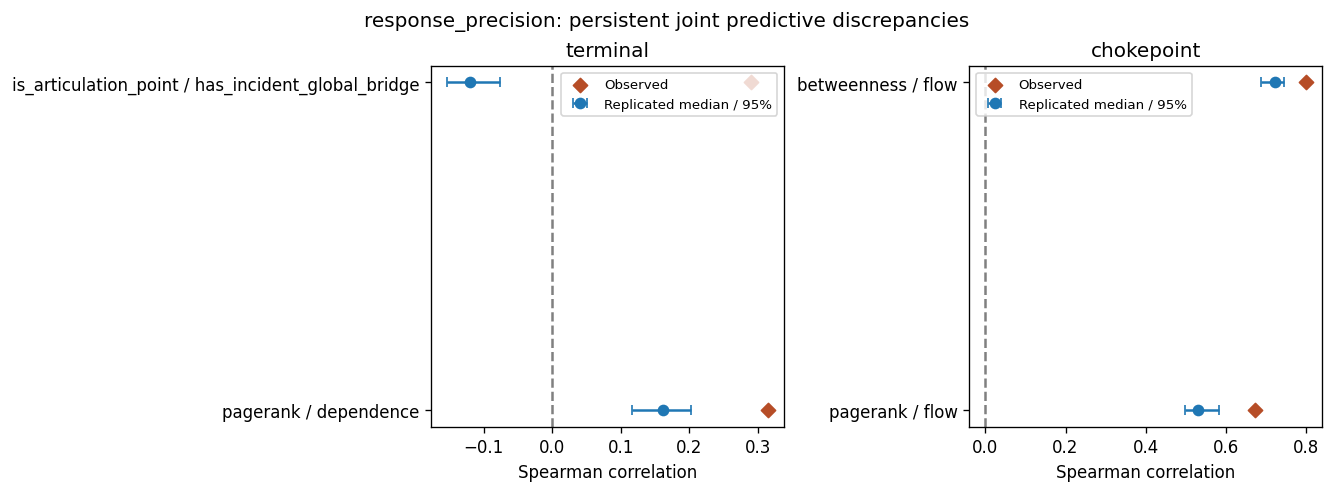

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(11,4),layout='constrained')
selected = {
 'terminal':['is_articulation_point / has_incident_global_bridge',
             'role_specific_pagerank / role_specific_dependence'],
 'chokepoint':['pagerank / share_monthly_network_flow',
               'betweenness / share_monthly_network_flow']}
for ax,kind in zip(axes,['terminal','chokepoint']):
    d=new_joint_checks[new_joint_checks.Model.eq(kind) & new_joint_checks.Pair.isin(selected[kind])].reset_index(drop=True)
    x=np.arange(len(d))
    ax.errorbar(d.RepMedian,x,xerr=[d.RepMedian-d.Low,d.High-d.RepMedian],fmt='o',capsize=3,label='Replicated median / 95%')
    ax.scatter(d.Observed,x,marker='D',color='#b64d27',label='Observed')
    ax.set_yticks(x,d.Pair.str.replace('role_specific_','',regex=False).str.replace('share_monthly_network_flow','flow',regex=False))
    ax.axvline(0,color='gray',ls='--'); ax.set_title(kind); ax.set_xlabel('Spearman correlation'); ax.legend(fontsize=8)
fig.suptitle('response_precision: persistent joint predictive discrepancies')
plt.show()


## 13. Cinque domande per il meeting
1. Il fattore terminale è una sintesi utile di centralità/diversificazione, anche se non riassume bene tutti gli indicatori strutturali?
2. La discrepanza articulation–bridge suggerisce di confrontare rango uno con un secondo fattore, oppure una dipendenza specifica tra indicatori?
3. Servono intercette/loading/precisioni specifici per ruolo, visto che la dummy modifica soltanto la media del fattore?
4. Prima di interpretare gli score, quanto cambiano i risultati con prior alternative e partenze più diverse?
5. Quale obiettivo ha l'estensione: rappresentazione del campione, traiettorie dinamiche o previsione di mesi futuri?

**Conclusione provvisoria:** campionamento soddisfacente secondo lo screening; likelihood compatibili con i supporti; fattori interpretabili; adeguatezza congiunta incompleta. Non abbiamo dimostrato che rango due sia necessario, né validato una classifica definitiva di criticality.

## Appendice — script corrente completo
La cella seguente conserva il testo completo aggiornato, con tre profili delle prior e lo rende consultabile. Non lo esegue e non invoca `main`. Le funzioni utilizzate sopra sono estratte dallo stesso script. L'entrypoint originale include validazioni, audit e metadati di riproducibilità ulteriori rispetto al fit opzionale del notebook.

In [ ]:
ORIGINAL_SCRIPT = '"""Static rank-one criticality models conditional on consecutive activity.\n\nSelect terminal or chokepoint with --node-type.\nChokepoints: Beta PageRank/flow share; zero-inflated Beta betweenness.\nChokepoint bridge indicator omitted (near duplicate of articulation).\n\nPageRank: Beta; HHI and dependence: one-inflated Beta, on original scale.\nInterior means and probabilities of one have distinct factor loadings.\nStructural responses: Bernoulli. Factor variance is one; PageRank loading positive.\nNo activity component, country, throughput, AR(1), or repeated-node effects.\nDefault priors use the regularized profile; --prior-profile original reproduces\nthe previous priors. Both profiles are provisional: check prior predictions\nand posterior sensitivity before interpreting scores.\n--prior-profile response_precision keeps regularized priors but uses\nresponse-specific Beta precision medians as a third sensitivity candidate.\nPlace this file in scripts/model/ to resolve the existing default panel paths.\n"""\n\nimport argparse\nimport inspect\nimport hashlib\nimport json\nfrom pathlib import Path\nimport warnings\nimport sys\nimport shutil\nimport platform\nfrom datetime import datetime, timezone\nfrom importlib.metadata import version, PackageNotFoundError\n\nimport numpy as np\nimport pandas as pd\n\n\nBASE_DIR = Path(__file__).resolve().parents[2]\nPANEL_DIR = BASE_DIR / "data" / "processed" / "model_ready"\nOUTPUT_DIR = BASE_DIR / "outputs" / "model" / "simple_criticality"\nBINARY_RESPONSES = [\n    "is_articulation_point", "has_incident_global_bridge",\n    "connected_to_articulation_point",\n]\nCOMMON_PREDICTORS = [\n    "neighbor_activity_lag1", "log1p_mean_voyage_distance_lag1",\n    "month_sin", "month_cos",\n]\nSPECS = {\n    "terminal": {\n        "id": "terminal_id",\n        "continuous": ["role_specific_pagerank", "counterparty_hhi_terminal",\n                       "role_specific_dependence"],\n        "binary": BINARY_RESPONSES.copy(),\n        "predictors": COMMON_PREDICTORS + ["log1p_capacity_mtpa", "terminal_age"],\n    },\n    "chokepoint": {\n        "id": "node_id",\n        "continuous": ["pagerank", "betweenness", "share_monthly_network_flow"],\n        "binary": ["is_articulation_point", "connected_to_articulation_point"],\n        "predictors": COMMON_PREDICTORS,\n    },\n}\n\n\ndef prior_specification(kind, profile="regularized"):\n    """Fixed candidate priors, not fitted to empirical response frequencies.\n\n    Keep the original intercept centres. Concentrate\n    small-response intercepts/loadings and boundary logits to reduce extreme\n    prior predictions. This is a sensitivity candidate, not a validated prior.\n    All scales below are standard deviations (HalfNormal: scale).\n    """\n    if kind not in SPECS or profile not in ("original", "regularized", "response_precision"):\n        raise ValueError("Unknown node type or prior profile")\n    original = profile == "original"\n    return {\n        "profile": profile,\n        "beta_sd": 0.5,\n        "pagerank_loading_sd": 1.0 if original else 0.5,\n        "other_loading_sd": ([1.0, 1.0] if original or kind == "terminal"\n                             else [0.5, 0.5]),\n        "binary_loading_sd": 1.0,\n        "interior_intercept_mean": ([-4.0, 0.0, 0.0] if kind == "terminal"\n                                    else [-4.0, -5.0, -4.0]),\n        "interior_intercept_sd": ([1.5, 1.5, 1.5] if original else\n                                  ([0.7, 1.5, 1.5] if kind == "terminal"\n                                   else [0.7, 0.7, 0.7])),\n        "binary_intercept_sd": 2.0,\n        "boundary_intercept_mean": 0.0 if kind == "terminal" else -5.0,\n        "boundary_intercept_sd": 1.5 if original else 1.0,\n        "boundary_loading_sd": 1.0 if original else 0.5,\n        # Candidate scales: at mu=.018, phi=300/500 gives conditional\n        # Beta SD approximately .0077/.0059. At mu=.01/.02, phi=100\n        # gives SD approximately .0099/.0139. These are illustrative\n        # conditional scales, not matches to marginal empirical SDs.\n        # Keep HHI/dependence unchanged to isolate small-response precision.\n        "precision_median": (([300.0, 10.0, 10.0] if kind == "terminal"\n                              else [500.0, 100.0, 100.0])\n                             if profile == "response_precision"\n                             else [10.0, 10.0, 10.0]),\n        "precision_response_order": SPECS[kind]["continuous"].copy(),\n    }\n\n\ndef standardize(frame):\n    """Fit scaling on the estimation sample; save it for interpretation/reuse."""\n    mean, sd = frame.mean(), frame.std(ddof=0)\n    if (sd <= 0).any() or not np.isfinite(sd).all():\n        raise ValueError(f"Constant/invalid columns: {sd.index[sd <= 0].tolist()}")\n    values = ((frame - mean) / sd).to_numpy(dtype=float)\n    return values, pd.DataFrame({"mean": mean, "sd": sd})\n\n\ndef prepare_panel(path, kind):\n    spec = SPECS[kind]\n    frame = pd.read_csv(path, dtype={spec["id"]: "string"})\n    needed = [spec["id"], "node_name", "period_month", "active",\n              "activity_lag1", "lag_available", *spec["predictors"],\n              *spec["continuous"], *spec["binary"]]\n    if kind == "terminal":\n        needed += ["terminal_role_lag1"]\n    missing = sorted(set(needed) - set(frame.columns))\n    if missing:\n        raise ValueError(f"{path.name}: missing columns {missing}")\n    keys = [spec["id"], "period_month"]\n    if frame[keys].isna().any().any() or frame.duplicated(keys).any():\n        raise ValueError(f"{path.name}: missing or duplicate node-month keys")\n    frame["period_month"] = pd.to_datetime(frame["period_month"], errors="raise")\n    if not frame["period_month"].dt.is_month_start.all():\n        raise ValueError("period_month must contain first-of-month dates")\n    for col in ["active", "lag_available"]:\n        if not frame[col].isin([0, 1]).all():\n            raise ValueError(f"{col} must be binary without missing values")\n    if not frame["activity_lag1"].dropna().isin([0, 1]).all():\n        raise ValueError("activity_lag1 must be binary where observed")\n    # Verify the supplied lag refers to the preceding CALENDAR month, not\n    # the previous selected active row. Do not recalculate any panel metric.\n    ordered = frame.sort_values(keys)\n    grouped = ordered.groupby(spec["id"], sort=False)\n    previous_month = grouped["period_month"].shift()\n    previous_active = grouped["active"].shift()\n    expected = previous_month.eq(ordered["period_month"] - pd.offsets.MonthBegin(1))\n    if not ordered["lag_available"].eq(expected.astype(int)).all():\n        raise ValueError("lag_available disagrees with calendar-month availability")\n    if not ordered.loc[expected, "activity_lag1"].eq(previous_active[expected]).all():\n        raise ValueError("activity_lag1 disagrees with previous calendar activity")\n    audit = {"panel_rows": len(frame), "panel_nodes": frame[spec["id"]].nunique()}\n    selected = frame.loc[frame["active"].eq(1)].copy()\n    audit["excluded_inactive_current"] = len(frame) - len(selected)\n    valid_lag = selected["lag_available"].eq(1)\n    audit["excluded_no_calendar_lag"] = int((~valid_lag).sum())\n    selected = selected.loc[valid_lag].copy()\n    previous_active_mask = selected["activity_lag1"].eq(1)\n    audit["excluded_inactive_previous"] = int((~previous_active_mask).sum())\n    selected = selected.loc[previous_active_mask].copy()\n    audit["consecutive_active_rows"] = len(selected)\n    audit["excluded_missing_age"] = 0\n    if kind == "terminal":\n        audit["excluded_missing_age"] = int(selected["terminal_age"].isna().sum())\n        selected = selected.loc[selected["terminal_age"].notna()].copy()\n        if selected["terminal_age"].lt(0).any():\n            raise ValueError("Negative terminal age: review the panel metadata")\n        if not selected["terminal_role_lag1"].isin(["importer", "exporter"]).all():\n            raise ValueError("Unexpected lagged role in consecutive-active sample")\n        selected["exporter_lag1"] = selected["terminal_role_lag1"].eq("exporter").astype(int)\n    selected = selected.sort_values(["period_month", spec["id"]]).reset_index(drop=True)\n    if selected.empty:\n        raise ValueError(f"No observations remain for {kind}")\n    predictors = spec["predictors"] + (["exporter_lag1"] if kind == "terminal" else [])\n    model_columns = predictors + spec["continuous"] + spec["binary"]\n    values = selected[model_columns].to_numpy(dtype=float)\n    if not np.isfinite(values).all():\n        raise ValueError(f"Unexpected missing/nonfinite model values: "\n                         f"{selected[model_columns].isna().sum().to_dict()}")\n    if not selected[spec["binary"]].isin([0, 1]).all().all():\n        raise ValueError("Structural responses must be binary")\n    if not selected[spec["continuous"]].ge(0).all().all() or not selected[spec["continuous"]].le(1).all().all():\n        raise ValueError("Continuous responses must lie in [0, 1]")\n    if selected[spec["binary"]].nunique().lt(2).any():\n        raise ValueError("A binary response is constant in the estimation sample")\n    # Center/scale numeric covariates; keep role dummy on its 0/1 scale.\n    x, x_scaling = standardize(selected[spec["predictors"]])\n    if kind == "terminal":\n        x = np.column_stack([x, selected["exporter_lag1"].to_numpy()])\n        x_scaling.loc["exporter_lag1"] = [0.0, 1.0]\n    yc, y_scaling = standardize(selected[spec["continuous"]])\n    audit.update(estimation_rows=len(selected), estimation_nodes=selected[spec["id"]].nunique(),\n                 predictors=predictors, continuous_responses=spec["continuous"],\n                 binary_responses=spec["binary"],\n                 input_sha256=hashlib.sha256(path.read_bytes()).hexdigest())\n    return {"frame": selected, "x": x, "yc": yc,\n            "yb": selected[spec["binary"]].to_numpy(dtype=int),\n            "x_scaling": x_scaling, "y_scaling": y_scaling, "audit": audit}\n\n\ndef one_inflated_beta_logp(value, alpha, beta, boundary_logit, inflated):\n    """Mixed measure: Lebesgue density on (0,1), point probability at one.\n\n    Substitute 0.5 ONLY in the unselected Beta branch for exact boundaries;\n    observations are never clipped, shifted, or replaced in the likelihood.\n    """\n    import pymc as pm\n    import pytensor.tensor as pt\n    inside = (value > 0) & (value < 1)\n    safe_value = pt.switch(inside, value, 0.5)\n    log_beta = pm.logp(pm.Beta.dist(alpha=alpha, beta=beta), safe_value)\n    log_one = -pt.logaddexp(0.0, -boundary_logit)\n    log_interior = -pt.logaddexp(0.0, boundary_logit)\n    continuous = log_beta + pt.switch(inflated, log_interior, 0.0)\n    return pt.switch(inside, continuous,\n                     pt.switch(pt.eq(value, 1) & inflated, log_one, -np.inf))\n\n\ndef one_inflated_beta_random(alpha, beta, boundary_logit, inflated, rng=None, size=None):\n    rng = np.random.default_rng() if rng is None else rng\n    # Stable sigmoid, including extreme logits in predictive draws.\n    prob = np.exp(-np.logaddexp(0.0, -np.asarray(boundary_logit)))\n    prob = np.where(inflated, prob, 0.0)\n    interior = rng.beta(alpha, beta, size=size)\n    # Floating-point beta routines may round to 0/1; keep interior draws interior.\n    interior = np.clip(interior, np.nextafter(0.0, 1.0), np.nextafter(1.0, 0.0))\n    return np.where(rng.uniform(size=np.shape(interior)) < prob, 1.0, interior)\n\n\ndef build_terminal_model(data):\n    import pymc as pm\n    import pytensor.tensor as pt\n\n    priors = prior_specification("terminal", data.get("prior_profile", "regularized"))\n    coords = {"obs": np.arange(len(data["frame"])),\n              "predictor": data["audit"]["predictors"],\n              "continuous": data["audit"]["continuous_responses"],\n              "other_continuous": data["audit"]["continuous_responses"][1:],\n              "binary": data["audit"]["binary_responses"],\n              "boundary": data["audit"]["continuous_responses"][1:]}\n    with pm.Model(coords=coords) as model:\n        beta = pm.Normal("beta", 0, priors["beta_sd"], dims="predictor")\n        factor_mean = pm.Deterministic("factor_mean", pt.dot(data["x"], beta), dims="obs")\n        factor = pm.Normal("factor", mu=factor_mean, sigma=1, dims="obs")\n        pm.Deterministic("factor_residual", factor - factor_mean, dims="obs")\n        # PageRank is the first response in both specifications.\n        anchor = pm.HalfNormal("pagerank_loading", priors["pagerank_loading_sd"])\n        other = pm.Normal("other_loadings", 0, priors["other_loading_sd"], dims="other_continuous")\n        lc = pm.Deterministic("loading_cont", pt.concatenate([anchor[None], other]), dims="continuous")\n        lb = pm.Normal("loading_binary", 0, priors["binary_loading_sd"], dims="binary")\n        ac = pm.Normal("intercept_cont", mu=priors["interior_intercept_mean"], sigma=priors["interior_intercept_sd"], dims="continuous")\n        ab = pm.Normal("intercept_binary", 0, priors["binary_intercept_sd"], dims="binary")\n        # Each response has its own precision; profile determines its prior median.\n        phi = pm.LogNormal("precision_cont", mu=np.log(priors["precision_median"]),\n                           sigma=data["precision_prior_sd"], dims="continuous")\n        boundary_intercept = pm.Normal("intercept_one", priors["boundary_intercept_mean"], priors["boundary_intercept_sd"], dims="boundary")\n        boundary_loading = pm.Normal("loading_one", 0, priors["boundary_loading_sd"], dims="boundary")\n        eta_one = boundary_intercept + factor[:, None] * boundary_loading\n        logits = pt.concatenate([pt.zeros_like(factor[:, None]), eta_one], axis=1)\n        mu = pm.math.sigmoid(ac + factor[:, None] * lc)\n        pm.CustomDist("y_cont", mu * phi, (1 - mu) * phi, logits,\n                      np.array([False, True, True]),\n                      logp=one_inflated_beta_logp, random=one_inflated_beta_random,\n                      observed=data["frame"][data["audit"]["continuous_responses"]].to_numpy(),\n                      dims=("obs", "continuous"))\n        pm.Bernoulli("y_binary", logit_p=ab + factor[:, None] * lb,\n                     observed=data["yb"], dims=("obs", "binary"))\n    return model\n\n\n\ndef zero_inflated_beta_logp(value, alpha, beta, boundary_logit, inflated):\n    # Reflecting the Beta and boundary gives exactly a zero-inflated Beta.\n    return one_inflated_beta_logp(1 - value, beta, alpha, boundary_logit, inflated)\n\n\ndef zero_inflated_beta_random(alpha, beta, boundary_logit, inflated, rng=None, size=None):\n    rng = np.random.default_rng() if rng is None else rng\n    prob = np.exp(-np.logaddexp(0.0, -np.asarray(boundary_logit)))\n    prob = np.where(inflated, prob, 0.0)\n    interior = np.clip(rng.beta(alpha, beta, size=size),\n                       np.nextafter(0.0, 1.0), np.nextafter(1.0, 0.0))\n    return np.where(rng.uniform(size=np.shape(interior)) < prob, 0.0, interior)\n\n\ndef build_chokepoint_model(data):\n    import pymc as pm\n    import pytensor.tensor as pt\n    priors = prior_specification("chokepoint", data.get("prior_profile", "regularized"))\n    coords = {"obs": np.arange(len(data["frame"])),\n              "predictor": data["audit"]["predictors"],\n              "continuous": data["audit"]["continuous_responses"],\n              "other_continuous": data["audit"]["continuous_responses"][1:],\n              "binary": data["audit"]["binary_responses"],\n              "boundary": ["betweenness"]}\n    with pm.Model(coords=coords) as model:\n        beta = pm.Normal("beta", 0, priors["beta_sd"], dims="predictor")\n        mean = pm.Deterministic("factor_mean", pt.dot(data["x"], beta), dims="obs")\n        factor = pm.Normal("factor", mean, 1, dims="obs")\n        pm.Deterministic("factor_residual", factor - mean, dims="obs")\n        anchor = pm.HalfNormal("pagerank_loading", priors["pagerank_loading_sd"])\n        other = pm.Normal("other_loadings", 0, priors["other_loading_sd"], dims="other_continuous")\n        lc = pm.Deterministic("loading_cont", pt.concatenate([anchor[None], other]), dims="continuous")\n        lb = pm.Normal("loading_binary", 0, priors["binary_loading_sd"], dims="binary")\n        ac = pm.Normal("intercept_cont", priors["interior_intercept_mean"], priors["interior_intercept_sd"], dims="continuous")\n        ab = pm.Normal("intercept_binary", 0, priors["binary_intercept_sd"], dims="binary")\n        phi = pm.LogNormal("precision_cont", np.log(priors["precision_median"]), data["precision_prior_sd"], dims="continuous")\n        azero = pm.Normal("intercept_zero", priors["boundary_intercept_mean"], priors["boundary_intercept_sd"], dims="boundary")\n        lzero = pm.Normal("loading_zero", 0, priors["boundary_loading_sd"], dims="boundary")\n        eta = azero + factor[:, None] * lzero\n        logits = pt.concatenate([pt.zeros_like(eta), eta, pt.zeros_like(eta)], axis=1)\n        mu = pm.math.sigmoid(ac + factor[:, None] * lc)\n        pm.CustomDist("y_cont", mu * phi, (1-mu)*phi, logits,\n                      np.array([False, True, False]),\n                      logp=zero_inflated_beta_logp, random=zero_inflated_beta_random,\n                      observed=data["frame"][data["audit"]["continuous_responses"]].to_numpy(),\n                      dims=("obs", "continuous"))\n        pm.Bernoulli("y_binary", logit_p=ab + factor[:, None]*lb,\n                     observed=data["yb"], dims=("obs", "binary"))\n    return model\n\n\ndef build_model(data):\n    return (build_terminal_model(data) if "exporter_lag1" in data["audit"]["predictors"]\n            else build_chokepoint_model(data))\n\n\ndef chokepoint_initial_values(data, chains, seed):\n    rng = np.random.default_rng(seed)\n    f = data["yc"][:, 0]\n    b = np.linalg.lstsq(data["x"], f, rcond=None)[0]\n    y = data["frame"][data["audit"]["continuous_responses"]]\n    means = np.array([y[c].loc[y[c].gt(0)].mean() for c in y])\n    p = np.clip(data["yb"].mean(axis=0), .01, .99)\n    pzero = y["betweenness"].eq(0).mean()\n    starts = []\n    for _ in range(chains):\n        starts.append({"beta": b+rng.normal(0,.03,b.shape),\n                       "factor": f+rng.normal(0,.05,f.shape),\n                       "pagerank_loading": float(rng.uniform(.6,.8)),\n                       "other_loadings": rng.normal(.2,.05,2),\n                       "loading_binary": rng.normal(0,.05,len(p)),\n                       "intercept_cont": np.log(means/(1-means))+rng.normal(0,.03,3),\n                       "intercept_binary": np.log(p/(1-p))+rng.normal(0,.03,len(p)),\n                       "precision_cont": np.asarray(prior_specification("chokepoint", data.get("prior_profile", "regularized"))["precision_median"])*np.exp(rng.normal(0,.03,3)),\n                       "intercept_zero": np.array([np.log(pzero/(1-pzero))])+rng.normal(0,.03,1),\n                       "loading_zero": rng.normal(0,.05,1)})\n    return starts\n\ndef predictive_checks(idata, data, group):\n    """Compare in-sample replicated distributions, on the original scale."""\n    draws = getattr(idata, group)\n    yc = draws["y_cont"].transpose("chain", "draw", "obs", "continuous").values\n    # Bounded responses are modelled directly on their original scale.\n    yb = draws["y_binary"].transpose("chain", "draw", "obs", "binary").values\n    rows = []\n    for j, col in enumerate(data["audit"]["continuous_responses"]):\n        observed = data["frame"][col].to_numpy()\n        replicated = yc[..., j]\n        rows.append({"response": col, "observed_mean": observed.mean(),\n                     "replicated_mean": replicated.mean(),\n                     "observed_sd": observed.std(), "replicated_sd": replicated.std(),\n                     "observed_zero_share": np.mean(observed == 0),\n                     "observed_one_share": np.mean(observed == 1),\n                     "replicated_outside_support_share": np.mean((replicated < 0) | (replicated > 1))})\n    for j, col in enumerate(data["audit"]["binary_responses"]):\n        proportions = yb[..., j].mean(axis=-1)\n        rows.append({"response": col, "observed_mean": data["yb"][:, j].mean(),\n                     "replicated_mean": proportions.mean(),\n                     "replicated_mean_q025": np.quantile(proportions, .025),\n                     "replicated_mean_q975": np.quantile(proportions, .975)})\n    # Quantities calculated separately for each replicated dataset, not pooled.\n    masks = {"all": np.ones(len(data["frame"]), dtype=bool)}\n    for role in (["importer", "exporter"] if "terminal_role_lag1" in data["frame"] else []):\n        masks[role] = data["frame"]["terminal_role_lag1"].eq(role).to_numpy()\n    for role, mask in masks.items():\n        if not mask.any():\n            continue\n        for j, col in enumerate(data["audit"]["continuous_responses"]):\n            obs = data["frame"][col].to_numpy()[mask]\n            rep = yc[..., mask, j]\n            statistics = {"mean": (obs.mean(), rep.mean(axis=-1)),\n                          "sd": (obs.std(), rep.std(axis=-1)),\n                          "one_share": ((obs == 1).mean(), (rep == 1).mean(axis=-1)),\n                          "zero_share": ((obs == 0).mean(), (rep == 0).mean(axis=-1))}\n            for q in [.05, .5, .95]:\n                statistics[f"q{int(q*100):02d}"] = (np.quantile(obs, q), np.quantile(rep, q, axis=-1))\n            for stat, (actual, replicated) in statistics.items():\n                rows.append({"response": col, "role_lag1": role, "statistic": stat,\n                             "observed": actual, "replicated_mean": replicated.mean(),\n                             "replicated_q025": np.quantile(replicated, .025),\n                             "replicated_q975": np.quantile(replicated, .975)})\n    return pd.DataFrame(rows)\n\n\ndef initial_values(data, chains, seed):\n    """Data-informed starting points only; priors and likelihoods stay unchanged.\n\n    Orient the initial factor toward PageRank, with small independent chain\n    perturbations. This does not prove that other posterior modes are absent.\n    """\n    rng = np.random.default_rng(seed)\n    factor_start = data["yc"][:, 0].copy()\n    beta_start = np.linalg.lstsq(data["x"], factor_start, rcond=None)[0]\n    loading = data["yc"].T @ factor_start / (factor_start @ factor_start)\n    # PageRank initializes the factor but must not start with zero noise.\n    probability = np.clip(data["yb"].mean(axis=0), 0.01, 0.99)\n    intercept_binary = np.log(probability / (1 - probability))\n    binary_loading = np.array([\n        (np.corrcoef(factor_start, data["yb"][:, j])[0, 1]\n         if data["yb"][:, j].std() > 0 else 0.0)\n        for j in range(data["yb"].shape[1])\n    ])\n    starts = []\n    for _ in range(chains):\n        starts.append({\n            "beta": beta_start + rng.normal(0, 0.03, beta_start.shape),\n            "factor": factor_start + rng.normal(0, 0.05, factor_start.shape),\n            "pagerank_loading": float(rng.uniform(0.6, 0.8)),\n            "other_loadings": loading[1:] + rng.normal(0, 0.03, loading[1:].shape),\n            "loading_binary": binary_loading + rng.normal(0, 0.03, binary_loading.shape),\n            "intercept_cont": np.array([\n                np.log(v / (1-v)) for v in [\n                    data["frame"][col].loc[data["frame"][col].lt(1)].mean()\n                    for col in data["audit"]["continuous_responses"]]]) + rng.normal(0, .03, 3),\n            "intercept_one": np.array([\n                np.log(v / (1-v)) for v in\n                data["frame"][data["audit"]["continuous_responses"][1:]].eq(1).mean()\n            ]) + rng.normal(0, .03, 2),\n            "loading_one": rng.normal(0, .05, 2),\n            "intercept_binary": intercept_binary + rng.normal(0, 0.03, probability.shape),\n            "precision_cont": np.asarray(prior_specification("terminal", data.get("prior_profile", "regularized"))["precision_median"]) * np.exp(rng.normal(0, .03, 3)),\n        })\n    return starts\n\n\ndef fit_model(data, kind, args, destination):\n    try:\n        import pymc as pm\n        import arviz as az\n    except ImportError as exc:\n        raise RuntimeError("Install scripts/model/requirements.txt to estimate the model") from exc\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n\n    model = build_model(data)\n    with model:\n        prior_count_key = ("draws" if "draws" in inspect.signature(pm.sample_prior_predictive).parameters\n                           else "samples")\n        prior = pm.sample_prior_predictive(**{prior_count_key: args.prior_draws}, random_seed=args.seed)\n        predictive_checks(prior, data, "prior_predictive").to_csv(destination / "prior_checks.csv", index=False)\n        prior.to_netcdf(destination / "prior.nc")\n        if args.prior_only:\n            return\n        idata = pm.sample(draws=args.draws, tune=args.tune, chains=args.chains,\n                          cores=args.cores, target_accept=args.target_accept,\n                          init="adapt_diag",\n                          initvals=(initial_values(data, args.chains, args.seed) if kind == "terminal"\n                                    else chokepoint_initial_values(data, args.chains, args.seed)),\n                          random_seed=args.seed, return_inferencedata=True)\n        if (idata.posterior.sizes["chain"] != args.chains\n                or idata.posterior.sizes["draw"] != args.draws):\n            idata.to_netcdf(destination / "interrupted_posterior.nc")\n            raise SystemExit("Incomplete sampling: saved interrupted_posterior.nc; "\n                             "stopping without replacing posterior.nc or fitting another model")\n        # Preserve completed sampling even if predictive simulation fails.\n        idata.to_netcdf(destination / "posterior.nc")\n        pm.sample_posterior_predictive(idata, var_names=["y_cont", "y_binary"],\n                                       random_seed=args.seed, extend_inferencedata=True)\n    idata.to_netcdf(destination / "posterior.nc")\n    parameters = ["beta", "loading_cont", "loading_binary", "intercept_cont",\n                  "intercept_binary", "precision_cont"] + (\n                      ["intercept_one", "loading_one"] if kind == "terminal"\n                      else ["intercept_zero", "loading_zero"])\n    summary = az.summary(idata, var_names=parameters, hdi_prob=.95)\n    summary.to_csv(destination / "parameter_summary.csv")\n    for chain in idata.posterior.coords["chain"].values:\n        az.summary(idata.sel(chain=[chain]), var_names=parameters,\n                   kind="stats", hdi_prob=.95).to_csv(\n                       destination / f"parameter_summary_chain_{chain}.csv")\n    # Include latent residual mixing: good global parameters alone are insufficient.\n    mixing = az.summary(idata, var_names=parameters + ["factor", "factor_mean", "factor_residual"], kind="diagnostics")\n    diagnostic = {"divergences": int(idata.sample_stats["diverging"].sum()),\n                  "max_rhat": float(mixing["r_hat"].max()),\n                  "min_ess_bulk": float(mixing["ess_bulk"].min()),\n                  "min_ess_tail": float(mixing["ess_tail"].min())}\n    diagnostic["nonfinite_diagnostic_entries"] = int(\n        (~np.isfinite(mixing[["r_hat", "ess_bulk", "ess_tail"]].to_numpy())).sum())\n    mixing.to_csv(destination / "mixing_diagnostics.csv")\n    diagnostic["passes_basic_checks"] = bool(\n        diagnostic["nonfinite_diagnostic_entries"] == 0 and diagnostic["divergences"] == 0\n        and np.isfinite(diagnostic["max_rhat"]) and diagnostic["max_rhat"] <= 1.01\n        and diagnostic["min_ess_bulk"] >= 400 and diagnostic["min_ess_tail"] >= 400)\n    (destination / "sampling_diagnostics.json").write_text(json.dumps(diagnostic, indent=2), encoding="utf-8")\n    if not diagnostic["passes_basic_checks"]:\n        warnings.warn(f"{kind}: sampling checks did not pass; do not interpret scores yet")\n    scores = data["frame"][[SPECS[kind]["id"], "node_name", "period_month"]].copy()\n    for variable in ["factor", "factor_mean"]:\n        samples = idata.posterior[variable].transpose("obs", "chain", "draw").values.reshape(len(scores), -1)\n        scores[f"{variable}_mean"] = samples.mean(axis=1)\n        scores[f"{variable}_q025"] = np.quantile(samples, .025, axis=1)\n        scores[f"{variable}_q975"] = np.quantile(samples, .975, axis=1)\n    scores["passes_basic_sampling_checks"] = diagnostic["passes_basic_checks"]\n    score_filename = ("factor_scores.csv" if diagnostic["passes_basic_checks"]\n                      else "factor_scores_UNVALIDATED.csv")\n    scores.to_csv(destination / score_filename, index=False)\n    predictive_checks(idata, data, "posterior_predictive").to_csv(destination / "posterior_checks.csv", index=False)\n    with az.rc_context({"plot.max_subplots": 100}):\n        az.plot_trace(idata, var_names=parameters, compact=False)\n    plt.savefig(destination / "trace.png", dpi=150, bbox_inches="tight")\n    plt.close("all")\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--terminal-panel", type=Path, default=PANEL_DIR / "terminal_criticality_model_panel.csv")\n    parser.add_argument("--chokepoint-panel", type=Path, default=PANEL_DIR / "chokepoint_criticality_model_panel.csv")\n    parser.add_argument("--output-dir", type=Path, default=OUTPUT_DIR)\n    parser.add_argument("--prior-profile", choices=["original", "regularized", "response_precision"],\n                        default="regularized", help="Original, regularized, or regularized with response-specific precision priors")\n    parser.add_argument("--precision-prior-sd", type=float, default=.7,\n                        help="Common log SD of Beta precision priors (medians depend on profile); try 1.0 for sensitivity")\n    parser.add_argument("--run-name", help="Optional new subfolder name; existing folders are never overwritten")\n    parser.add_argument("--node-type", choices=["terminal", "chokepoint"], default="terminal")\n    parser.add_argument("--check-only", action="store_true", help="Validate/filter panels without PyMC or writing datasets")\n    parser.add_argument("--prior-only", action="store_true", help="Save prior predictive checks without fitting")\n    parser.add_argument("--draws", type=int, default=1000)\n    parser.add_argument("--tune", type=int, default=2000)\n    parser.add_argument("--chains", type=int, default=4)\n    parser.add_argument("--cores", type=int, default=1, help="One core is portable to Windows; increase if desired")\n    parser.add_argument("--prior-draws", type=int, default=200)\n    parser.add_argument("--target-accept", type=float, default=.95)\n    parser.add_argument("--seed", type=int, default=20261008)\n    args = parser.parse_args()\n    if min(args.draws, args.tune, args.chains, args.cores, args.prior_draws) < 1:\n        parser.error("Sampling counts must be positive")\n    if not 0 < args.target_accept < 1:\n        parser.error("target-accept must be between 0 and 1")\n    if args.run_name and (args.run_name in (".", "..") or\n                          any(c in args.run_name for c in \'/\\\\:\')):\n        parser.error("run-name must be a single folder name")\n    if not np.isfinite(args.precision_prior_sd) or args.precision_prior_sd <= 0:\n        parser.error("precision-prior-sd must be finite and positive")\n    kinds = [args.node_type]\n    # Validate all selected inputs before starting any potentially expensive fit.\n    data = {kind: prepare_panel(getattr(args, f"{kind}_panel"), kind) for kind in kinds}\n    for kind, item in data.items():\n        item["precision_prior_sd"] = args.precision_prior_sd\n        item["prior_profile"] = args.prior_profile\n        item["audit"]["prior_specification"] = {**prior_specification(kind, args.prior_profile),\n                                                  "precision_log_sd": args.precision_prior_sd}\n        item["audit"]["response_likelihood_scale"] = "original (0,1]"\n        item["audit"]["response_scaling_purpose"] = "initial values only; not used in likelihood"\n        y = item["frame"][item["audit"]["continuous_responses"]]\n        if kind == "terminal":\n            if y.eq(0).any().any() or y.iloc[:, 0].ge(1).any():\n                raise ValueError("Terminal model requires positive responses and PageRank below one")\n            if any(not 0 < v < 1 for v in y.iloc[:, 1:].eq(1).mean()):\n                raise ValueError("Each inflated response needs boundary and interior observations")\n        else:\n            item["audit"]["response_likelihood_scale"] = "original [0,1)"\n            if y.ge(1).any().any() or y[["pagerank", "share_monthly_network_flow"]].le(0).any().any():\n                raise ValueError("Chokepoint PageRank/flow must be interior; no response may equal one")\n            if not 0 < y["betweenness"].eq(0).mean() < 1:\n                raise ValueError("Betweenness requires both zeros and interior observations")\n            item["audit"]["excluded_binary_response"] = "has_incident_global_bridge: near duplicate of articulation"\n        item["audit"]["boundary_counts"] = {c: {"zeros": int(y[c].eq(0).sum()),\n                                                       "ones": int(y[c].eq(1).sum())} for c in y}\n        print(f"{kind}: {item[\'audit\'][\'estimation_rows\']} observations, "\n              f"{item[\'audit\'][\'estimation_nodes\']} nodes")\n    if args.check_only:\n        print(json.dumps({kind: item["audit"] for kind, item in data.items()}, indent=2))\n        return\n    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")\n    run = args.output_dir / (args.run_name or f"{stamp}_{args.node_type}_bounded_{args.prior_profile}")\n    run.mkdir(parents=True, exist_ok=False)\n    print(f"Run directory: {run.resolve()}", flush=True)\n    script_path = Path(__file__).resolve()\n    shutil.copy2(script_path, run / "estimation_script.py")\n    packages = {}\n    for package in ["numpy", "pandas", "pymc", "pytensor", "arviz", "matplotlib"]:\n        try:\n            packages[package] = version(package)\n        except PackageNotFoundError:\n            packages[package] = None\n    config = {**vars(args), "likelihood": ("Beta PageRank; one-inflated Beta HHI/dependence" if args.node_type == "terminal"\n                                       else "Beta PageRank/flow; zero-inflated Beta betweenness"),\n              "prior_specification": prior_specification(args.node_type, args.prior_profile),\n              "precision_prior": {"distribution": "LogNormal",\n                                  "median_by_response": dict(zip(SPECS[args.node_type]["continuous"],\n                                      prior_specification(args.node_type, args.prior_profile)["precision_median"])),\n                                  "log_sd": args.precision_prior_sd},\n              "started_utc": stamp, "command_argv": sys.argv,\n              "python": platform.python_version(), "packages": packages,\n              "script_sha256": hashlib.sha256(script_path.read_bytes()).hexdigest()}\n    (run / "run_config.json").write_text(json.dumps(config, default=str, indent=2), encoding="utf-8")\n    for kind, item in data.items():\n        destination = run / kind\n        destination.mkdir(exist_ok=True)\n        (destination / "sample_audit.json").write_text(json.dumps(item["audit"], indent=2), encoding="utf-8")\n        item["x_scaling"].to_csv(destination / "predictor_scaling.csv")\n        item["y_scaling"].to_csv(destination / "response_scaling.csv")\n        item["frame"][item["audit"]["binary_responses"]].corr().to_csv(destination / "binary_correlations.csv")\n        status_path = destination / "run_status.json"\n        def write_status(status, **details):\n            status_path.write_text(json.dumps({"status": status, **details}, indent=2), encoding="utf-8")\n        write_status("running")\n        try:\n            fit_model(item, kind, args, destination)\n        except BaseException as exc:\n            write_status("incomplete_or_failed", error_type=type(exc).__name__, error=str(exc))\n            raise\n        if args.prior_only:\n            write_status("prior_only_complete")\n        else:\n            diagnostics = json.loads((destination / "sampling_diagnostics.json").read_text())\n            write_status("sampling_complete", passes_basic_sampling_checks=diagnostics["passes_basic_checks"],\n                         note="Passing sampling checks does not establish model adequacy.")\n    print(f"Results saved to {run}")\n\n\nif __name__ == "__main__":\n    main()\n'
print("Script corrente conservato:",len(ORIGINAL_SCRIPT.splitlines()),"righe")
# display(Markdown("```python\n" + ORIGINAL_SCRIPT + "\n```"))

def prior_specification(kind, profile="regularized"):
    """Fixed candidate priors, not fitted to empirical response frequencies.

    Keep the original intercept centres. Concentrate
    small-response intercepts/loadings and boundary logits to reduce extreme
    prior predictions. This is a sensitivity candidate, not a validated prior.
    All scales below are standard deviations (HalfNormal: scale).
    """
    if kind not in SPECS or profile not in ("original", "regularized", "response_precision"):
        raise ValueError("Unknown node type or prior profile")
    original = profile == "original"
    return {
        "profile": profile,
        "beta_sd": 0.5,
        "pagerank_loading_sd": 1.0 if original else 0.5,
        "other_loading_sd": ([1.0, 1.0] if original or kind == "terminal"
                             else [0.5, 0.5]),
        "binary_loading_sd": 1.0,
        "interior_intercept_mean": ([-4.0, 0.0, 0.0] if kind == "terminal"
                                    else [-4.0, -5.0, -4.0]),
        "interior_intercept_sd": ([1.5, 1.5, 1.5] if original else
                                  ([0.7, 1.5, 1.5] if kind == "terminal"
                                   else [0.7, 0.7, 0.7])),
        "binary_intercept_sd": 2.0,
        "boundary_intercept_mean": 0.0 if kind == "terminal" else -5.0,
        "boundary_intercept_sd": 1.5 if original else 1.0,
        "boundary_loading_sd": 1.0 if original else 0.5,
        # Candidate scales: at mu=.018, phi=300/500 gives conditional
        # Beta SD approximately .0077/.0059. At mu=.01/.02, phi=100
        # gives SD approximately .0099/.0139. These are illustrative
        # conditional scales, not matches to marginal empirical SDs.
        # Keep HHI/dependence unchanged to isolate small-response precision.
        "precision_median": (([300.0, 10.0, 10.0] if kind == "terminal"
                              else [500.0, 100.0, 100.0])
                             if profile == "response_precision"
                             else [10.0, 10.0, 10.0]),
        "precision_response_order": SPECS[kind]["continuous"].copy(),
    }